[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/05.%20Linear%20Models%20and%20Regularization/ch05_linear_models.ipynb)

# Chapter 5: Linear Models and Regularization

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 5, pp. 116–145

**What you will learn in this chapter:**
- How ordinary least squares (OLS) linear regression works, and how to fit and evaluate it
- How Ridge (L2) and Lasso (L1) regularization shrink coefficients, and how Lasso selects features
- How ElasticNet blends both penalties, and how to read coefficient-path plots
- The theory behind regularization: model complexity, overfitting and the bias–variance trade-off
- How polynomial regression and spline regression model non-linear relationships (and how to avoid overfitting them)
- Three practical exercises implementing Ridge, Lasso and ElasticNet

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Linear models | Fit $y=\beta_0+\sum\beta_jx_j$ by least squares | `LinearRegression` |
| Ridge and Lasso | Add an L2 / L1 penalty on the coefficients | `Ridge`, `Lasso` (`alpha`) |
| ElasticNet | Mix L1 and L2 | `ElasticNet` (`alpha`, `l1_ratio`) |
| Regularization theory | Trade a little bias for a big drop in variance | — |
| Regression and regularization | Non-linear fits from linear models | `PolynomialFeatures`, `SplineTransformer` |
| Practical exercises | Ridge, Lasso, ElasticNet on synthetic data | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text, code or conclusions are inaccurate are flagged with
**Book correction** (collected again at the end). This chapter has the most of them, because the book's first synthetic dataset has a flaw that
changes how its results must be read — it is diagnosed in Section 1.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to linear models

**Summary.** A linear model predicts the target as a weighted sum of the features:
$$\hat y=\beta_0+\beta_1x_1+\dots+\beta_px_p$$
**Ordinary Least Squares (OLS)** chooses the coefficients that minimise the sum of squared errors $\sum_i (y_i-\hat y_i)^2$. It is the foundation for regularised regression (this chapter)
and logistic regression (Chapter 6).

### Getting ready — the book's synthetic dataset
`make_regression` creates 1 000 samples with 100 features, of which only 10 are truly informative, plus noise. The book then (a) makes columns 50–99 *correlated* copies of columns 0–49,
and (b) scales the target and adds a sine and an exponential term.

> **Book correction (reproducibility).** The loop that builds the correlated features uses `np.random.normal` *without a seed*, so the data differs on every run.
> I add `np.random.seed(123)` before it; otherwise the code is the book's.

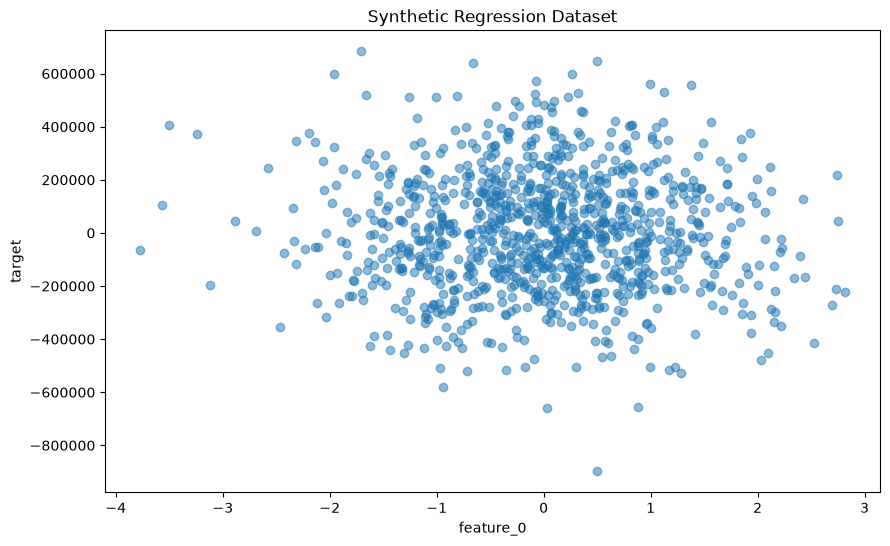

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# 2. Create a synthetic regression dataset with high multicollinearity and more features
X, y = make_regression(n_samples=1000,
                       n_features=100,
                       n_informative=10,
                       noise=20,
                       random_state=123)

# 3. Add multicollinearity by creating correlated features
np.random.seed(123)                      # (added for reproducibility; not in the book)
for i in range(50, 100): # Make half the features correlated
    X[:, i] = X[:, i-50] + np.random.normal(0, 0.1, size=1000)

# 4. Create feature names
feature_names = [f'feature_{i}' for i in range(100)]

# 5. Take just the first feature for visualization
X_plot = X[:, 0].reshape(-1, 1)

# 6. Add some non-linearity and make coefficients vary widely in magnitude
y = y * 1000  # Scale up the target
y = (y + np.sin(X_plot.ravel()) * 150
     + np.exp(X_plot.ravel()/10))

# 7. Convert data arrays to a pandas DataFrame with feature names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df_plot = pd.DataFrame({
    'feature_0': X_plot.ravel(), 'target': y
})

# 8. Create a quick visualization of the data
plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Synthetic Regression Dataset')
plt.show()

The scatter of one feature against the target looks like a shapeless cloud — expected, because each single feature explains only a small part of `y`
(the target depends on several features at once).

### How to do it…
Split, fit `LinearRegression`, evaluate with the **mean squared error (MSE)** and **R²**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=123
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')

Mean Squared Error: 46550591070.53
R-squared: 0.06


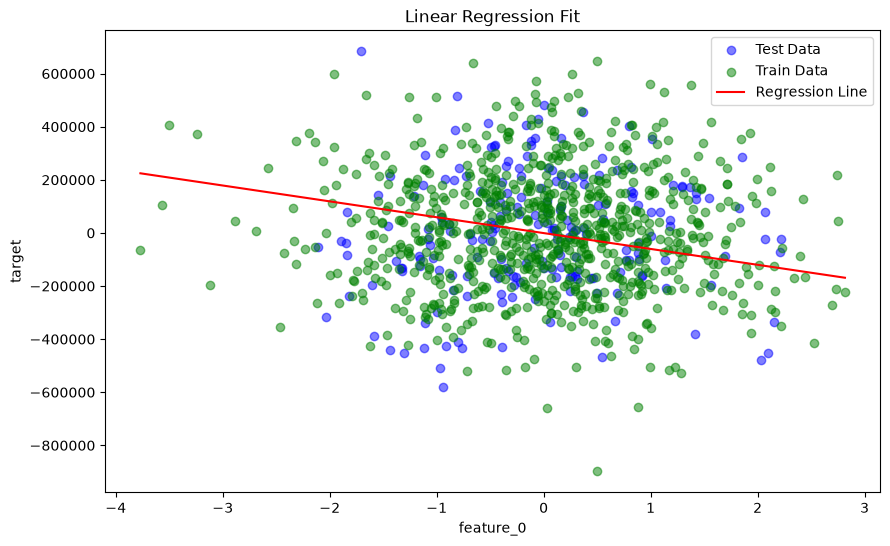

In [4]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_test[:, 0], y_test, color='blue',
    alpha=0.5, label='Test Data'
)
plt.scatter(
    X_train[:, 0], y_train, color='green',
    alpha=0.5, label='Train Data'
)

# Sort the data for a smooth line plot
X_line = np.linspace(
    df['feature_0'].min(),
    df['feature_0'].max(), 100
).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()  # Set feature_0, leave others as 0
# (the book wraps this in a DataFrame, but the model was fitted on a NumPy array -> a feature-name warning; an array is used here)
y_line = linear_model.predict(X_line_full)
plt.plot(X_line, y_line, color='red', label='Regression Line')

plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

The red "line" is the model's prediction when feature_0 varies and **all 99 other features are held at 0** — a slice through a 100-dimensional hyperplane, so it cannot look like it fits a 2-D scatter.
The R² of the whole model is the real measure, and it is very low (≈ 0.07–0.1; the book prints 0.09). **Why?** The book's later text blames "high multicollinearity". Let us check.

### Extension — diagnosing the dataset
`make_regression(..., coef=True)` returns the true coefficients, so we can see which columns actually drive `y`, and which of them the book's loop **overwrote**.

In [5]:
_, _, true_coef = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=20, random_state=123, coef=True)
informative = np.flatnonzero(true_coef)
overwritten = informative[informative >= 50]
print("truly informative columns :", informative.tolist())
print("overwritten by the loop   :", overwritten.tolist(), f"-> {len(overwritten)} of {len(informative)} informative columns destroyed")

# same dataset BEFORE the overwrite loop (target scaled the same way)
X_orig, y_orig = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=20, random_state=123)
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(X_orig, y_orig * 1000, test_size=0.2, random_state=123)
print("\nOLS R2 on the book's data          :", round(linear_model.score(X_test, y_test), 3))
print("OLS R2 on the same data, not overwritten:", round(LinearRegression().fit(Xo_tr, yo_tr).score(Xo_te, yo_te), 3))

truly informative columns : [3, 21, 25, 66, 68, 71, 75, 81, 98, 99]
overwritten by the loop   : [66, 68, 71, 75, 81, 98, 99] -> 7 of 10 informative columns destroyed

OLS R2 on the book's data          : 0.065
OLS R2 on the same data, not overwritten: 0.992


> **Book correction (important).** The target `y` is generated from the *original* features, and only afterwards does the loop replace columns 50–99 with noisy copies of columns 0–49.
> Because `make_regression` scatters its 10 informative columns randomly, **7 of the 10 informative columns (66, 68, 71, 75, 81, 98, 99) were overwritten**: their signal is gone from `X` while still present in `y`.
> That — not multicollinearity — is why every model scores R² ≈ 0.1 (versus 0.99 without the overwrite). Multicollinearity makes coefficients unstable; it does not make the model unable to predict.
> The book's conclusions in the next recipes ("ElasticNet is better than the three previous models") therefore compare models on data that is almost pure noise.

**Extension — the dataset the book *meant* to build.** Keep every informative column and create the correlated copies from the *uninformative* columns. I keep the original target scale (no ×1000) so the regularisation strengths behave sensibly (see Section 2).

In [6]:
rng = np.random.default_rng(123)
uninformative = np.flatnonzero(true_coef == 0)
targets = uninformative[:50]                              # 50 uninformative columns to overwrite ...
sources = np.resize(informative, 50)                      # ... with noisy copies of the informative ones
X_good = X_orig.copy()
X_good[:, targets] = X_orig[:, sources] + rng.normal(0, 0.1, size=(1000, 50))
y_good = y_orig

Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_good, y_good, test_size=0.2, random_state=123)
print("OLS R2 on the rebuilt, genuinely multicollinear data:", round(LinearRegression().fit(Xg_tr, yg_tr).score(Xg_te, yg_te), 3))
print("max |correlation| between an informative column and its copy:",
      round(max(abs(np.corrcoef(X_good[:, s], X_good[:, t])[0, 1]) for s, t in zip(sources, targets)), 3))

OLS R2 on the rebuilt, genuinely multicollinear data: 0.992
max |correlation| between an informative column and its copy: 0.995


Now there is strong signal **and** strong multicollinearity (corr ≈ 0.99 between a signal column and its copy) — the situation the chapter wants to illustrate. OLS still *predicts* well (R² ≈ 0.99) but its coefficients are unreliable: **Extension — multicollinearity in miniature**
(two almost identical features; bootstrap the fit and look at how much the coefficients move):

In [7]:
rng = np.random.default_rng(0)
n = 200
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.05, size=n)                  # almost a duplicate of x1
Xm = np.c_[x1, x2]
ym = 3 * x1 + rng.normal(scale=1.0, size=n)               # only x1 truly matters (coefficient 3)

from sklearn.linear_model import Ridge
coefs = {"OLS": [], "Ridge(alpha=10)": []}
for _ in range(300):
    idx = rng.integers(0, n, n)                           # bootstrap resample
    coefs["OLS"].append(LinearRegression().fit(Xm[idx], ym[idx]).coef_)
    coefs["Ridge(alpha=10)"].append(Ridge(alpha=10).fit(Xm[idx], ym[idx]).coef_)

print("condition number of X'X:", f"{np.linalg.cond(Xm.T @ Xm):,.0f}")
for name, c in coefs.items():
    c = np.array(c)
    print(f"{name:16s} coef_x1 mean={c[:, 0].mean():6.2f} sd={c[:, 0].std():5.2f} | coef_x2 mean={c[:, 1].mean():6.2f} sd={c[:, 1].std():5.2f} | sum of the two = {c.sum(axis=1).mean():.2f}")

condition number of X'X: 1,394
OLS              coef_x1 mean=  1.90 sd= 1.37 | coef_x2 mean=  1.17 sd= 1.37 | sum of the two = 3.07
Ridge(alpha=10)  coef_x1 mean=  1.50 sd= 0.05 | coef_x2 mean=  1.48 sd= 0.04 | sum of the two = 2.99


OLS cannot tell the two copies apart: each individual coefficient varies a lot from sample to sample (standard deviation ≈ 1.4, with the two coefficients trading off against each other), although their **sum stays ≈ 3**
(the predictions are fine). Ridge splits the weight evenly and keeps the estimates stable (standard deviation ≈ 0.05, about 30× smaller) — the reason regularisation is recommended for collinear data.
(The condition number here is modest because the copies differ by noise of sd 0.05; with exact or near-exact duplicates it grows without bound.)

### How it works…
The model is $y=\beta_0+\beta_1x_1+\dots+\beta_px_p+\epsilon$ with $\beta_0$ the intercept, $\beta_j$ the coefficients and $\epsilon$ the error. **Extension — OLS from the normal equation** reproduces scikit-learn exactly:

In [8]:
Xd = np.c_[np.ones(len(X_train)), X_train]                          # add a column of ones for the intercept
beta = np.linalg.solve(Xd.T @ Xd, Xd.T @ y_train)                   # (X'X) beta = X'y
print("intercept: manual", round(beta[0], 4), "| sklearn", round(linear_model.intercept_, 4))
print("max |coef difference|:", np.abs(beta[1:] - linear_model.coef_).max())

intercept: manual -628.3077 | sklearn -628.3077
max |coef difference|: 7.887138053774834e-09


**Extension — residual diagnostics.** A good linear fit leaves residuals that look like structureless noise around 0 (no pattern against the prediction, roughly normal):

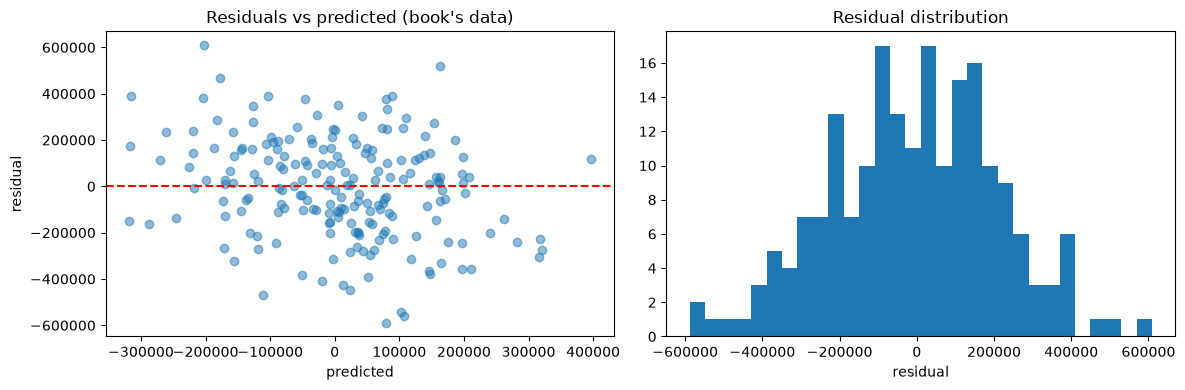

residual std: 215,647 | target std: 223,102 -> the model removes almost none of the variance


In [9]:
res = y_test - y_pred
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_pred, res, alpha=.5); ax[0].axhline(0, c="r", ls="--"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("residual"); ax[0].set_title("Residuals vs predicted (book's data)")
ax[1].hist(res, bins=30); ax[1].set_title("Residual distribution"); ax[1].set_xlabel("residual")
plt.tight_layout(); plt.show()
print("residual std:", f"{res.std():,.0f}", "| target std:", f"{y_test.std():,.0f}", "-> the model removes almost none of the variance")

### Theory
* **OLS.** Minimise $\mathrm{RSS}(\beta)=\lVert y-X\beta\rVert^2$. Setting the gradient to zero gives the **normal equations** $X^\top X\beta=X^\top y$, i.e. $\hat\beta=(X^\top X)^{-1}X^\top y$ — which exists only if $X^\top X$ is invertible.
  (scikit-learn uses an SVD-based least-squares solver, more stable than inverting.)
* **Assumptions** for reliable *inference*: linearity, independent errors, constant error variance (homoscedasticity), roughly normal errors, and **no (near-)perfect multicollinearity**. Prediction is more forgiving than interpretation.
* **Multicollinearity** makes $X^\top X$ nearly singular (huge condition number): $\mathrm{Var}(\hat\beta)=\sigma^2(X^\top X)^{-1}$ explodes, so coefficients become unstable and uninterpretable while predictions stay fine.
* **Metrics.** $\mathrm{MSE}=\frac1n\sum(y_i-\hat y_i)^2$ (units of $y^2$ — here $\approx10^{10}$ because $y$ was scaled ×1000); $R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$.
* **Errors in the book's workflow list:** "Load `LinearRegression()` … fit … predict … MSE and R² … plot predicted vs actual or residuals" — the residual plot above is that last step.
* **Limits.** OLS overfits when $p$ is large relative to $n$ and cannot be fitted at all if $p>n$. That motivates regularisation.

### There's more… (book)
Regularised regression (Ridge, Lasso — next section) and logistic regression (Chapter 6, an extension of linear models to class probabilities).

### Hands-on workflow (from the book)
Choose a regression dataset → clean/encode → fit `LinearRegression` → predict → MSE and R² → plot predicted vs actual or residuals (done above on the book's data; the exercises at the end use fresh data).

## 2. Ridge and Lasso regression

**Summary.** *Regularization* adds a penalty on the size of the coefficients to the loss, discouraging overly complex models and reducing overfitting. The strength is the hyper-parameter `alpha`.

| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalty | $\alpha\sum_j\beta_j^2$ | $\alpha\sum_j\lvert\beta_j\rvert$ |
| Effect | shrinks all coefficients, rarely to exactly 0 | shrinks and sets some to **exactly 0** (feature selection) |
| Use when | keep all features, correlated predictors | many irrelevant/redundant features |

### How to do it… (the book's data, book's hyper-parameters)

In [10]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

ridge_model = Ridge(alpha=1.0)  # alpha controls regularization strength
ridge_model.fit(X_train, y_train)

lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

# Make predictions with all models
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
y_pred_linear = linear_model.predict(X_test)

metrics = {
    'Model': [
        'Ridge Regression',
        'Lasso Regression',
        'Linear Regression'
    ],
    'Mean Squared Error': [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear)
    ],
    'R-squared': [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear)
    ]
}

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values(
    'Mean Squared Error', ascending=True)

metrics_df['Mean Squared Error'] = metrics_df[
    'Mean Squared Error'
].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df[
    'R-squared'
].map('{:.2f}'.format)
display(metrics_df)

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45341091794.40,0.09
1,Lasso Regression,46377111017.93,0.07
2,Linear Regression,46550591070.53,0.06


The book's table (Figure 5.3) reads Ridge 0.11, Lasso 0.09, Linear 0.09 (R²). Our numbers are of the same size — all three models are poor and within a hair of each other, because of the overwritten signal found in Section 1.
Now the book's comparison plot (again a slice with the other 99 features at 0):

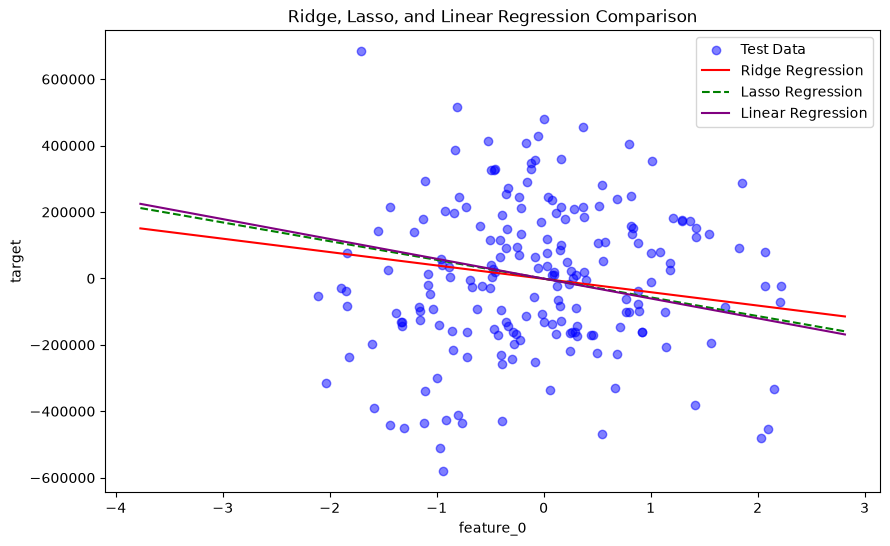

In [11]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_test[:, 0], y_test, color='blue',
    alpha=0.5, label='Test Data'
)
X_line = np.linspace(
    df['feature_0'].min(),
    df['feature_0'].max(), 100
).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()

y_line_ridge = ridge_model.predict(X_line_full)
y_line_lasso = lasso_model.predict(X_line_full)
y_line_linear = linear_model.predict(X_line_full)
plt.plot(X_line, y_line_ridge, color='red',
         label='Ridge Regression')
plt.plot(X_line, y_line_lasso, color='green',
         linestyle='--', label='Lasso Regression')
plt.plot(X_line, y_line_linear, color='purple',
         label='Linear Regression')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Ridge, Lasso, and Linear Regression Comparison')
plt.legend()
plt.show()

The three lines nearly coincide ("the difference … is negligible", as the book says).
The book then argues that "even small differences in predictive power can have significant impacts" — but here the differences (0.07 vs 0.09 R²) are far inside the noise of a single split.

**Extension — what did the penalties actually do to the coefficients?**

In [12]:
coef_table = pd.DataFrame({
    "OLS": linear_model.coef_, "Ridge(1)": ridge_model.coef_, "Lasso(10)": lasso_model.coef_,
}, index=feature_names)
print("coefficients exactly 0 :", (coef_table == 0).sum().to_dict())
print("mean |coefficient|     :", coef_table.abs().mean().round(1).to_dict())
print("sum of squared coefs   :", {k: f"{v:.3g}" for k, v in (coef_table ** 2).sum().items()})

coefficients exactly 0 : {'OLS': 0, 'Ridge(1)': 0, 'Lasso(10)': 0}
mean |coefficient|     : {'OLS': 52081.6, 'Ridge(1)': 40094.7, 'Lasso(10)': 50016.5}
sum of squared coefs   : {'OLS': '4.71e+11', 'Ridge(1)': '2.73e+11', 'Lasso(10)': '4.46e+11'}


Lasso zeroes some coefficients, Ridge only shrinks slightly. But the sizes involve numbers around $10^3$–$10^4$ because $y$ was multiplied by 1000 — and **that matters for `alpha`** (see below).

> **Book correction (scale of `alpha`).** `alpha` only means something *relative to the scale of the data*. In scikit-learn the Lasso objective is
> $\frac1{2n}\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_1$ — the data term is of order $\sigma_y^2\approx10^{10}$ here, so `alpha=10` or `alpha=1` is a vanishingly small penalty.
> The book's choice of `alpha` values (1, 10) was not tuned; with a target on this scale they barely regularise. The right workflow is to **select `alpha` by cross-validation** (`RidgeCV`, `LassoCV`, `ElasticNetCV`):

In [13]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def evaluate(name, model, Xtr, Xte, ytr, yte):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(Xtr, ytr)
    p = model.predict(Xte)
    est = model[-1] if hasattr(model, "steps") else model
    nz = int((np.abs(est.coef_) > 1e-8).sum())
    return {"model": name, "test R2": r2_score(yte, p), "test RMSE": np.sqrt(mean_squared_error(yte, p)), "non-zero coefs": nz,
            "alpha": getattr(est, "alpha_", np.nan)}

def compare(Xtr, Xte, ytr, yte):
    rows = [
        evaluate("OLS", LinearRegression(), Xtr, Xte, ytr, yte),
        evaluate("RidgeCV", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 4, 30))), Xtr, Xte, ytr, yte),
        evaluate("LassoCV", make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=123, max_iter=20000)), Xtr, Xte, ytr, yte),
        evaluate("ElasticNetCV", make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .5, .9], cv=5, random_state=123, max_iter=20000)), Xtr, Xte, ytr, yte),
    ]
    return pd.DataFrame(rows).set_index("model")

print("The book's (corrupted) data:")
display(compare(X_train, X_test, y_train, y_test).round(3))
print("The rebuilt data (strong signal + real multicollinearity):")
display(compare(Xg_tr, Xg_te, yg_tr, yg_te).round(3))

The book's (corrupted) data:


,test R2,test RMSE,non-zero coefs,alpha
model,,,,
OLS,0.065,215755.860,100,NaN
RidgeCV,0.143,206510.253,100,356.225
LassoCV,0.205,198878.824,14,9933.525
ElasticNetCV,0.057,216632.658,99,110.373


The rebuilt data (strong signal + real multicollinearity):


,test R2,test RMSE,non-zero coefs,alpha
model,,,,
OLS,0.992,20.534,100,NaN
RidgeCV,0.992,20.394,100,0.149
LassoCV,0.993,19.127,37,0.654
ElasticNetCV,0.992,20.474,94,0.110


* On the **book's data** (most of the signal destroyed) every model is poor (R² 0.06–0.2). `LassoCV` does best (≈ 0.2) because it discards most of the noise columns (keeps 14 of 100) and so keeps the few that still carry signal; Ridge/ElasticNet keep ~all 100 columns and shrink them.
* On the **rebuilt data** every method predicts equally well (R² ≈ 0.99); regularisation's benefit here is **sparsity and stability**, not accuracy: Lasso keeps 37 of the 100 coefficients that OLS uses.

**Extension — the clearest picture of Ridge vs Lasso: coefficient paths** on the real *Diabetes* data (10 standardised features). As `alpha` grows Ridge coefficients shrink smoothly towards 0 but stay non-zero;
Lasso coefficients hit exactly 0 one after another.

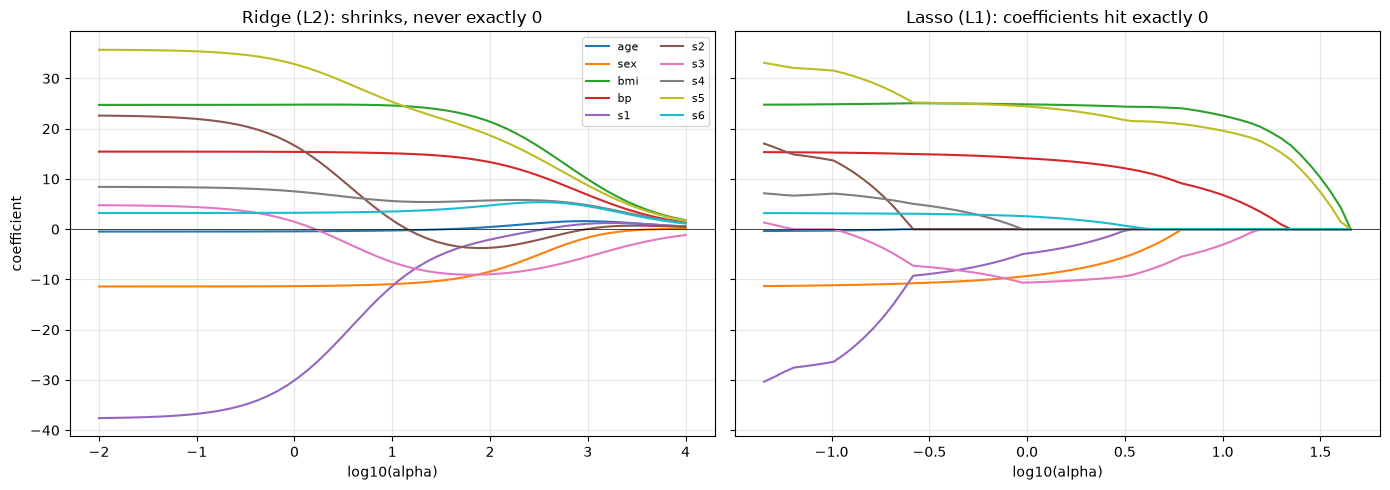

Lasso: the alpha at which each feature leaves the model (larger alpha = more important):
s5     40.17
bmi    40.17
bp     19.90
s3     14.00
sex     6.17
s6      3.86
s1      3.06
s4      0.95
age     0.23
s2      0.23


In [14]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import lasso_path

Xdb, ydb = load_diabetes(return_X_y=True, as_frame=True)
Xs = StandardScaler().fit_transform(Xdb)
alpha_max = np.abs(Xs.T @ (ydb.values - ydb.values.mean())).max() / len(ydb)      # smallest alpha at which every Lasso coefficient is 0
alphas_l, coefs_l, _ = lasso_path(Xs, ydb.values, alphas=np.logspace(np.log10(alpha_max), np.log10(alpha_max * 1e-3), 60))
alphas_r = np.logspace(-2, 4, 60)
coefs_r = np.array([Ridge(alpha=a).fit(Xs, ydb).coef_ for a in alphas_r]).T

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for c, n in zip(coefs_r, Xdb.columns): ax[0].plot(np.log10(alphas_r), c, label=n)
ax[0].set_title("Ridge (L2): shrinks, never exactly 0"); ax[0].set_xlabel("log10(alpha)"); ax[0].set_ylabel("coefficient"); ax[0].legend(ncol=2, fontsize=8)
for c, n in zip(coefs_l, Xdb.columns): ax[1].plot(np.log10(alphas_l), c, label=n)
ax[1].set_title("Lasso (L1): coefficients hit exactly 0"); ax[1].set_xlabel("log10(alpha)")
for a in ax: a.axhline(0, c="k", lw=.5); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

order = [Xdb.columns[i] for i in np.argsort(-np.abs(coefs_l).sum(axis=1)) ]
first_zero = {n: alphas_l[np.where(np.abs(c) > 1e-10)[0].min()] for n, c in zip(Xdb.columns, coefs_l)}
print("Lasso: the alpha at which each feature leaves the model (larger alpha = more important):")
print(pd.Series(first_zero).sort_values(ascending=False).round(2).to_string())

The Lasso order in which features drop out is a feature-importance ranking (here `s5` — a blood-serum measure — and `bmi` are the last to go), a by-product that Ridge does not provide.

**Extension — why scale before regularising.** The penalty treats every coefficient the same, so a feature measured on a large numeric scale (needing only a tiny coefficient) is *penalised less*:

In [15]:
rng = np.random.default_rng(1)
f = rng.normal(size=300)
Xsc = np.c_[f, f * 100]                                   # the same information, in two different units
ysc = 3 * f + rng.normal(scale=1, size=300)

raw = Lasso(alpha=0.5).fit(Xsc, ysc)
scaled = make_pipeline(StandardScaler(), Lasso(alpha=0.5)).fit(Xsc, ysc)[-1]
print("Lasso without scaling coefs :", raw.coef_.round(4), "-> keeps the large-scale copy, drops the small-scale one")
print("Lasso after standardising   :", scaled.coef_.round(3), "-> the two columns are now identical, so the units no longer decide")

Lasso without scaling coefs : [0.    0.031] -> keeps the large-scale copy, drops the small-scale one
Lasso after standardising   : [2.359 0.   ] -> the two columns are now identical, so the units no longer decide


Without scaling, the Lasso keeps the copy measured in the larger unit because it needs a tiny coefficient (cheap under the penalty): **units decide the selection**. After standardising, the two columns are identical,
so the penalty cannot prefer either by units; Lasso puts the whole weight on one of them (an arbitrary tie-break) — a reminder that Lasso is arbitrary among perfectly correlated features (ElasticNet's grouping effect, below, addresses that).
Always put a `StandardScaler` in front of Ridge/Lasso/ElasticNet (Chapter 2).

### How it works…
* **Ridge:** $\mathcal L=\sum_i(y_i-\hat y_i)^2+\alpha\sum_j\beta_j^2$. **Lasso:** $\mathcal L=\sum_i(y_i-\hat y_i)^2+\alpha\sum_j\lvert\beta_j\rvert$.
* Rule of thumb from the book: **Ridge** if you want to keep all features but reduce their impact; **Lasso** if you suspect many are irrelevant or redundant.

> **Book correction (formulas vs scikit-learn).** The book's loss formulas are the textbook form. scikit-learn minimises slightly different, rescaled objectives, so its `alpha` is *not* the book's $\alpha$:
> Ridge: $\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_2^2$ (as in the book) but **Lasso:** $\frac1{2n}\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_1$ (note the $\frac1{2n}$).

### Theory
* **Closed form for Ridge.** $\hat\beta_{ridge}=(X^\top X+\alpha I)^{-1}X^\top y$ — adding $\alpha I$ makes the matrix invertible and well-conditioned, which is why Ridge cures multicollinearity.
  Checked against scikit-learn (centred data, so no intercept term is needed):

In [16]:
Xc = Xs - Xs.mean(axis=0); yc = ydb.values - ydb.values.mean()
alpha = 5.0
w_manual = np.linalg.solve(Xc.T @ Xc + alpha * np.eye(Xc.shape[1]), Xc.T @ yc)
w_sklearn = Ridge(alpha=alpha).fit(Xs, ydb).coef_
print("max |manual - sklearn| =", np.abs(w_manual - w_sklearn).max())

max |manual - sklearn| = 1.7763568394002505e-13


* **Why does L1 give exact zeros and L2 not?** Geometrically the constraint region $\sum\lvert\beta_j\rvert\le t$ is a diamond with corners on the axes; the elliptical contours of the RSS typically first touch it at a corner, where some coordinates are 0.
  The L2 region is a sphere with no corners. Algebraically: the L2 penalty's gradient $2\alpha\beta_j$ vanishes as $\beta_j\to0$ (weak pull near 0), while the L1 gradient $\alpha\,\mathrm{sign}(\beta_j)$ stays constant (a steady pull that can reach exactly 0 — "soft-thresholding").
* **Bayesian view.** Ridge = MAP estimate with a **Gaussian** prior on the coefficients; Lasso = a **Laplace** prior (sharply peaked at 0, hence sparse solutions).
* **Lasso caveats:** with a group of strongly correlated features it tends to keep one arbitrarily and drop the rest (see ElasticNet); it can select at most $n$ features when $p>n$.
* **Solvers:** Ridge has a closed form (or iterative `sag`/`lsqr`); Lasso/ElasticNet use coordinate descent (hence `max_iter`/`tol`, and convergence warnings when `alpha` is tiny).

### Hands-on workflow (from the book)
Dataset → pre-process → fit `Ridge` → metrics → fit `Lasso` → metrics → analyse how regularisation changes each model (done above, plus CV-selected `alpha`).

## 3. ElasticNet and regularization

**Summary.** ElasticNet mixes the L1 and L2 penalties. `alpha` sets the overall strength and `l1_ratio` the mix: `l1_ratio=1` is (almost) Lasso, `l1_ratio→0` is (almost) Ridge. It is
designed for data with groups of correlated features and for $p>n$.

### How to do it… — coefficient paths
The book fits ElasticNet over a grid of `alpha` (7 values) × `l1_ratio` (5 values) and draws every feature's coefficient against $\log_{10}(\alpha)$.

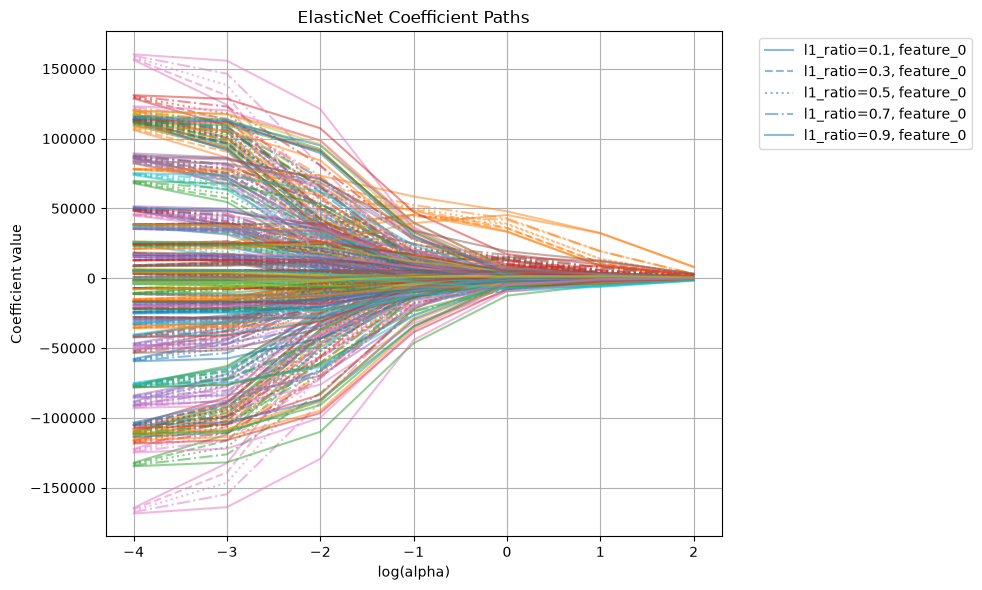

In [17]:
from sklearn.linear_model import ElasticNet

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

coef_paths = []
labels = []

plt.figure(figsize=(10, 6))
for l1_ratio in l1_ratios:
    coefs = []
    for alpha in alphas:
        elastic_model = ElasticNet(
            alpha=alpha, l1_ratio=l1_ratio,
            random_state=123, max_iter=10000, tol=1e-4
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")          # coordinate descent may warn at tiny alpha
            elastic_model.fit(X_train, y_train)
        coefs.append(elastic_model.coef_)

    coef_paths.append(np.array(coefs))

    for feature_idx in range(X_train.shape[1]):
        plt.plot(
            np.log10(alphas),
            np.array(coefs)[:, feature_idx],
            label=(
                f'l1_ratio={l1_ratio}, '
                f'feature_{feature_idx}'
                if feature_idx == 0 else ""
            ),
            alpha=0.5,
            linestyle=[
                'solid', 'dashed',
                'dotted', 'dashdot', '-'
            ][l1_ratios.index(l1_ratio)])
plt.xlabel('log(alpha)')
plt.ylabel('Coefficient value')
plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

The plot is hard to read (500 overlapping lines, as the book admits) and — more importantly — **it shows almost no shrinkage at all**: the lines are flat across the whole `alpha` range. The book's explanation says
"some coefficients go to exactly 0 … the paths help identify which features are most important". Let us count the exact zeros:

In [18]:
ys_train = (y_train - y_train.mean()) / y_train.std()           # same target, standardised to unit variance
rows = []
for a in alphas:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        z_book = (ElasticNet(alpha=a, l1_ratio=0.9, max_iter=10000, tol=1e-4, random_state=123).fit(X_train, y_train).coef_ == 0).sum()
        z_std = (ElasticNet(alpha=a, l1_ratio=0.9, max_iter=10000, tol=1e-4, random_state=123).fit(X_train, ys_train).coef_ == 0).sum()
    rows.append({"alpha": a, "zero coefs (book's y, scale ~1e4)": int(z_book), "zero coefs (standardised y)": int(z_std)})
pd.DataFrame(rows).set_index("alpha")

,"zero coefs (book's y, scale ~1e4)",zero coefs (standardised y)
alpha,,
0.0001,0,2
0.0010,0,28
0.0100,0,53
0.1000,0,96
1.0000,0,100
10.0000,0,100
100.0000,0,100


> **Book correction.** With the book's target (standard deviation ≈ $10^4$) **no coefficient is ever exactly 0, at any `alpha` up to 100** — the penalty is negligible next to the data term,
> so the "Key insights" listed in the book (coefficients shrinking, some going to 0, different `l1_ratio` giving different patterns) do **not** appear in its own figure. They appear once the target is on a unit scale (second column:
> from 2 zeros at `alpha=1e-4` to all 100 at `alpha≥1`). The lesson again: `alpha` must be chosen *relative to the data scale*, and the target should be standardised (or `alpha` chosen by `ElasticNetCV`).

A readable version of the same idea — **Extension: a clean path plot** on the rebuilt data with standardised features/target, highlighting the 10 truly informative features and showing how `l1_ratio` changes the picture:

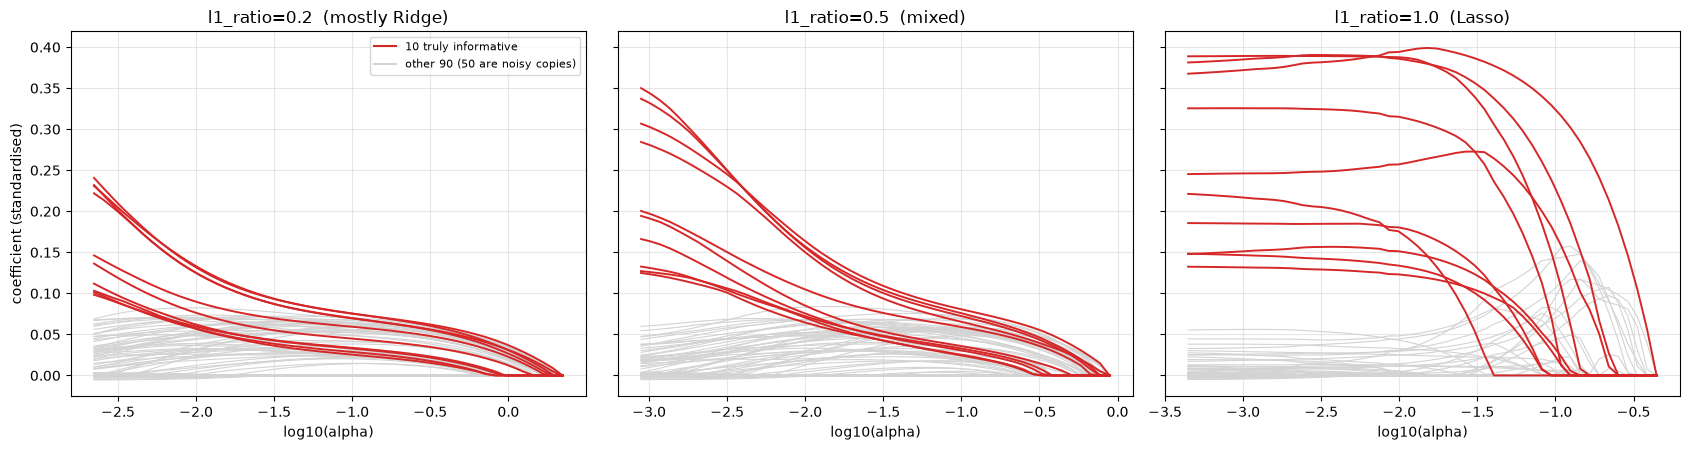

In [19]:
from sklearn.linear_model import enet_path

Xgs = StandardScaler().fit_transform(X_good)
ygs = (y_good - y_good.mean()) / y_good.std()
is_inf = np.zeros(100, dtype=bool); is_inf[informative] = True

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, l1r in zip(axes, (0.2, 0.5, 1.0)):
    a_max = np.abs(Xgs.T @ ygs).max() / (len(ygs) * l1r)                       # alpha above which all coefficients are 0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a_path, c_path, _ = enet_path(Xgs, ygs, l1_ratio=l1r, alphas=np.logspace(np.log10(a_max), np.log10(a_max * 1e-3), 50))
    for j in np.flatnonzero(~is_inf): ax.plot(np.log10(a_path), c_path[j], c="lightgrey", lw=.8)
    for j in informative: ax.plot(np.log10(a_path), c_path[j], c="tab:red", lw=1.4)
    for j in np.flatnonzero(np.isin(np.arange(100), targets)): pass
    ax.set_title(f"l1_ratio={l1r}  ({'Lasso' if l1r == 1 else 'mostly Ridge' if l1r < .5 else 'mixed'})"); ax.set_xlabel("log10(alpha)"); ax.grid(alpha=.3)
axes[0].set_ylabel("coefficient (standardised)")
axes[0].plot([], [], c="tab:red", label="10 truly informative"); axes[0].plot([], [], c="lightgrey", label="other 90 (50 are noisy copies)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Reading it: the x-axis is $\log_{10}\alpha$, so **moving right = stronger regularisation**, and every coefficient is driven to 0. The informative features (red) persist longest.
With `l1_ratio=1.0` (pure Lasso) the paths reach exactly 0 one by one; with a small `l1_ratio` (mostly Ridge) they shrink smoothly and many stay non-zero until very large `alpha`.
Each panel uses its own `alpha` range (the largest useful `alpha` scales with `1/l1_ratio`), so compare the *shapes*, not the horizontal positions.

### The model from the book (alpha=1, l1_ratio=0.5)

In [20]:
elastic_model = ElasticNet(
    alpha=1.0, l1_ratio=0.5, random_state=123,
    max_iter=10000, tol=1e-4
)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

new_row = pd.DataFrame({
    'Model': ['ElasticNet Regression'],
    'Mean Squared Error': [elastic_mse],
    'R-squared': [elastic_r2]
})

# rebuild the numeric comparison table (the earlier one was converted to strings)
metrics_num = pd.DataFrame(metrics)
metrics_num = metrics_num[~metrics_num['Model'].str.contains('ElasticNet')]
metrics_num = pd.concat([metrics_num, new_row], ignore_index=True)
metrics_num = metrics_num.sort_values('Mean Squared Error', ascending=True)
display(metrics_num.style.format({'Mean Squared Error': '{:.2f}', 'R-squared': '{:.2f}'}))

,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,42616635365.79,0.14
0,Ridge Regression,45341091794.40,0.09
1,Lasso Regression,46377111017.93,0.07
2,Linear Regression,46550591070.53,0.06


In the book ElasticNet comes first (R² 0.14 vs 0.11/0.09/0.09, "better than our three previous models"); we see the same ordering. **But is this real?** With the signal mostly destroyed, the model that shrinks hardest
simply predicts closer to the mean. Check on the *rebuilt* data, where there is signal, and with repeated cross-validation instead of one split:

In [21]:
from sklearn.model_selection import cross_val_score, RepeatedKFold

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=123)
def cv_r2(model, X, y):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return cross_val_score(model, X, y, cv=rkf, scoring="r2")

models = {"OLS": LinearRegression(), "Ridge(alpha=1)": Ridge(1.0), "Lasso(alpha=10)": Lasso(10.0, max_iter=10000, tol=1e-3),
          "ElasticNet(1, 0.5)": ElasticNet(1.0, l1_ratio=0.5, max_iter=10000, tol=1e-4, random_state=123)}
rows = {}
for name, m in models.items():
    a = cv_r2(m, X, y); b = cv_r2(m, X_good, y_good)
    rows[name] = {"book data: mean R2": a.mean(), "book data: sd": a.std(), "rebuilt data: mean R2": b.mean(), "rebuilt data: sd": b.std()}
pd.DataFrame(rows).T.round(3)

,book data: mean R2,book data: sd,rebuilt data: mean R2,rebuilt data: sd
OLS,0.103,0.077,0.991,0.001
Ridge(alpha=1),0.130,0.071,0.991,0.001
Lasso(alpha=10),0.107,0.076,0.968,0.004
"ElasticNet(1, 0.5)",0.184,0.040,0.983,0.002


Two lessons:
1. On the **book's data** (little signal) the untuned ElasticNet does have a modest edge in repeated CV (mean R² ≈ 0.18 vs 0.10 for OLS, with fold-to-fold sd 0.04–0.08): when the data is mostly noise, any model that shrinks hard predicts closer to the mean
   and so wins by a small margin. That is a statement about *shrinkage on noise*, not about ElasticNet's superiority.
2. On the **rebuilt data** (strong signal), the book's untuned `Lasso(alpha=10)` (0.968) and `ElasticNet(alpha=1)` (0.983) are both *worse* than plain OLS and Ridge(1) (0.991): the penalty is large relative to a target of scale ≈ 100, so they over-shrink.
   "ElasticNet is better" depends on the dataset and on untuned hyper-parameters. Tune `alpha` and `l1_ratio` by cross-validation (`ElasticNetCV`, shown earlier).

### How it works…
$$\min_\beta\ \frac1{2n}\lVert y-X\beta\rVert^2+\alpha\Big(\rho\lVert\beta\rVert_1+\frac{1-\rho}{2}\lVert\beta\rVert_2^2\Big),\qquad \rho=\texttt{l1\_ratio}.$$
(The book writes the penalty with two weights $\lambda_1,\lambda_2$; scikit-learn's parametrisation uses one overall strength `alpha` and a mixing ratio $\rho$ so that both are tuned independently.)
`l1_ratio=1` → Lasso, `l1_ratio=0` → Ridge (scikit-learn recommends using `Ridge` directly for 0, since coordinate descent is slow and unreliable there).

**Extension — the "grouping effect" ElasticNet was designed for.** With a strongly correlated pair, Lasso picks one arbitrarily; ElasticNet shares the weight between them:

In [22]:
rng = np.random.default_rng(3)
n = 300
base = rng.normal(size=n)
Xgrp = np.c_[base + rng.normal(scale=0.05, size=n), base + rng.normal(scale=0.05, size=n), rng.normal(size=(n, 3))]   # cols 0,1 are near-duplicates
ygrp = 2 * Xgrp[:, 0] + 2 * Xgrp[:, 1] + rng.normal(size=n)
for name, m in {"Lasso(0.3)": Lasso(0.3), "ElasticNet(0.3, l1_ratio=0.5)": ElasticNet(0.3, l1_ratio=0.5), "Ridge(10)": Ridge(10)}.items():
    print(f"{name:30s} coefs of the correlated pair: {m.fit(Xgrp, ygrp).coef_[:2].round(2)}   other 3 features: {m.coef_[2:].round(2)}")

Lasso(0.3)                     coefs of the correlated pair: [2.67 0.9 ]   other 3 features: [-0. -0. -0.]
ElasticNet(0.3, l1_ratio=0.5)  coefs of the correlated pair: [1.75 1.72]   other 3 features: [-0. -0. -0.]
Ridge(10)                      coefs of the correlated pair: [1.94 1.86]   other 3 features: [-0.03 -0.03 -0.03]


Lasso keeps the pair's total effect but concentrates it on one or two arbitrary members; ElasticNet and Ridge spread it more evenly. When correlated features are interchangeable, the spread solution is more stable from sample to sample.

### Theory
* **Why combine?** L1 gives sparsity but is unstable with correlated predictors and can pick at most $n$ variables; L2 stabilises and groups correlated variables but never selects. ElasticNet (Zou & Hastie, 2005) gets both.
* **Choosing hyper-parameters:** search `alpha` on a log grid and `l1_ratio` in a few values (e.g. `[.1, .5, .7, .9, .95, 1]`) with cross-validation (`ElasticNetCV`); standardise features first.
* **Coefficient path plots** show the entire regularisation spectrum at a glance: the order in which features enter/leave, and which are stable. The `lasso_path`/`enet_path` functions compute them far faster than refitting.

### Hands-on workflow (from the book)
Dataset → pre-process → `ElasticNet` → metrics → vary `alpha` and `l1_ratio` → plot predicted vs actual or coefficient paths (done above).

## 4. Regularization theory and practice

**Summary.** Regularization is "almost always" used in practice. It adds a penalty to the loss so the model cannot become too complex or lean too heavily on specific features,
trading fit on the training data for **generalisation** to new data. The book's building blocks:

1. **Model complexity** — the capacity to fit many functions. High capacity can memorise the training set (*overfitting*).
2. **Types:** **L1** (Lasso, sparse, feature selection), **L2** (Ridge, shrinks all, keeps all), **ElasticNet** (both; good for correlated features and when predictors outnumber observations).
3. **Bias–variance trade-off.** Regularisation slightly *increases bias* but *substantially reduces variance*; the aim is the level of regularisation with the lowest error on unseen data.

**Extension — see the trade-off.** A small-$n$, large-$p$ problem (60 samples, 50 features) is where OLS overfits badly. Plot training and test error as the Ridge penalty grows:

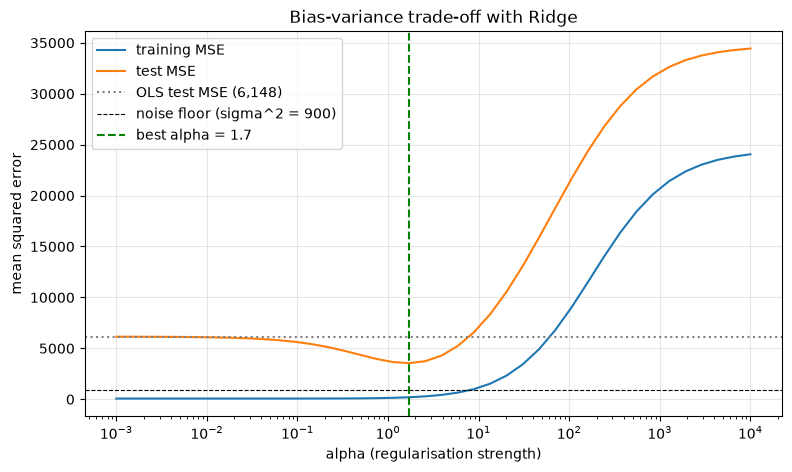

OLS test MSE 6,148  ->  best Ridge test MSE 3,550  (42% lower)


In [23]:
Xbv, ybv, coef_bv = make_regression(n_samples=1060, n_features=50, n_informative=10, noise=30, random_state=123, coef=True)
Xbv_tr, ybv_tr, Xbv_te, ybv_te = Xbv[:60], ybv[:60], Xbv[60:], ybv[60:]       # only 60 training points, 1000 fresh test points

alphas_bv = np.logspace(-3, 4, 40)
tr_err, te_err, coef_err = [], [], []
for a in alphas_bv:
    m = Ridge(alpha=a).fit(Xbv_tr, ybv_tr)
    tr_err.append(mean_squared_error(ybv_tr, m.predict(Xbv_tr))); te_err.append(mean_squared_error(ybv_te, m.predict(Xbv_te)))
ols_te = mean_squared_error(ybv_te, LinearRegression().fit(Xbv_tr, ybv_tr).predict(Xbv_te))

plt.figure(figsize=(9, 5))
plt.semilogx(alphas_bv, tr_err, label="training MSE"); plt.semilogx(alphas_bv, te_err, label="test MSE")
plt.axhline(ols_te, c="grey", ls=":", label=f"OLS test MSE ({ols_te:,.0f})"); plt.axhline(30 ** 2, c="k", ls="--", lw=.8, label="noise floor (sigma^2 = 900)")
best = alphas_bv[int(np.argmin(te_err))]; plt.axvline(best, c="g", ls="--", label=f"best alpha = {best:.2g}")
plt.xlabel("alpha (regularisation strength)"); plt.ylabel("mean squared error"); plt.title("Bias-variance trade-off with Ridge"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"OLS test MSE {ols_te:,.0f}  ->  best Ridge test MSE {min(te_err):,.0f}  ({1 - min(te_err) / ols_te:.0%} lower)")

The left of the plot (tiny `alpha`, ≈ OLS): training error is almost zero but test error is huge — **overfitting (high variance)**. Moving right, training error rises (a little bias is introduced) while test error falls to a minimum near the green line.
Beyond it the model is too constrained: both errors rise — **underfitting (high bias)**. With only 60 samples for 50 features, even the best Ridge stays well above the noise floor (≈ 3 500 vs 900); regularisation removes about 40 % of OLS's error but cannot create information that 60 samples do not contain.

### Theory
* **Expected test error** decomposes as $\mathbb E[(y-\hat f(x))^2]=\underbrace{\mathrm{Bias}^2}_{\text{model too simple}}+\underbrace{\mathrm{Var}}_{\text{model too sensitive to the sample}}+\underbrace{\sigma^2}_{\text{irreducible noise}}$.
  Regularisation moves the model along this trade-off; `alpha` is the dial.
* **Regularisation as a constraint:** penalised form $\min \mathrm{RSS}+\alpha\,P(\beta)$ is equivalent to minimising RSS subject to $P(\beta)\le t$ — a budget on the coefficients.
* **Practical recipe:** standardise features → choose the penalty family (Ridge for correlated/dense signal, Lasso for sparse signal, ElasticNet for both) → choose `alpha` by cross-validation on the **training** set → evaluate once on a test set.
* **Beyond the book:** group Lasso (select whole feature groups), Bayesian regression (priors on coefficients — scikit-learn's `BayesianRidge`, `ARDRegression`), early stopping and dropout are all regularisers in other model families.

### Hands-on workflow
Fit an unregularised model and note the train/test gap → add a penalty → tune `alpha` by CV → compare the gap (done above).

## 5. Regression and regularization: polynomial regression and splines

**Summary.** Linear models are linear in the *coefficients*, not necessarily in the features: add transformed features and the same least-squares machinery fits curves.
Two approaches: **polynomial regression** (powers of $x$) and **spline regression** (piecewise polynomials joined smoothly).

### Getting ready — a non-linear dataset
$y = 2x + 27\sin(x/8) + \varepsilon$, with $\varepsilon\sim N(0, 4^2)$: a linear trend plus a sine wave, 1 000 points on $x\in[-50,50]$.

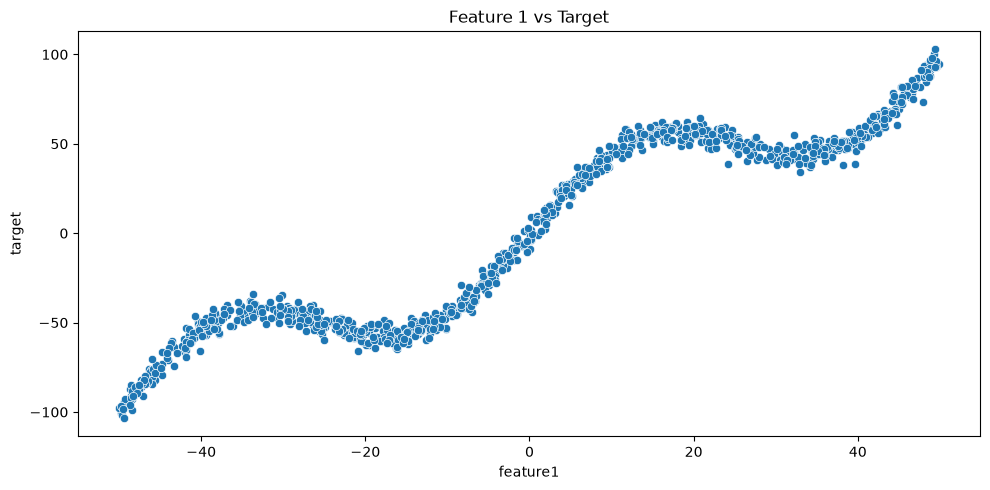

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))

y = (2 * X[:, 0]  # linear component
     + 27 * np.sin(X[:, 0] / 8)
     + np.random.normal(0, 4, n_samples))  # noise

data = pd.DataFrame(X, columns=['feature1'])
data['target'] = y

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='feature1', y='target')
plt.title('Feature 1 vs Target')
plt.tight_layout()
plt.show()

Note the **noise floor**: the irreducible error is the noise variance $4^2=16$. No model can have a (test) MSE below ≈ 16 — useful for judging "how good is good enough" below.

### Polynomial regression — how to do it…
Fit degrees 1–5, evaluate on a test split.

In [25]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = data[['feature1']]
y = data['target']

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X_poly, y, test_size=0.2, random_state=123)

    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)

    y_pred = poly_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Degree': degree,
        'MSE': mse,
        'R2': r2
    })

results_df = pd.DataFrame(results)
print("\nModel Performance Metrics:")
print(results_df.to_string(index=False))


Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5 811.070884 0.721464


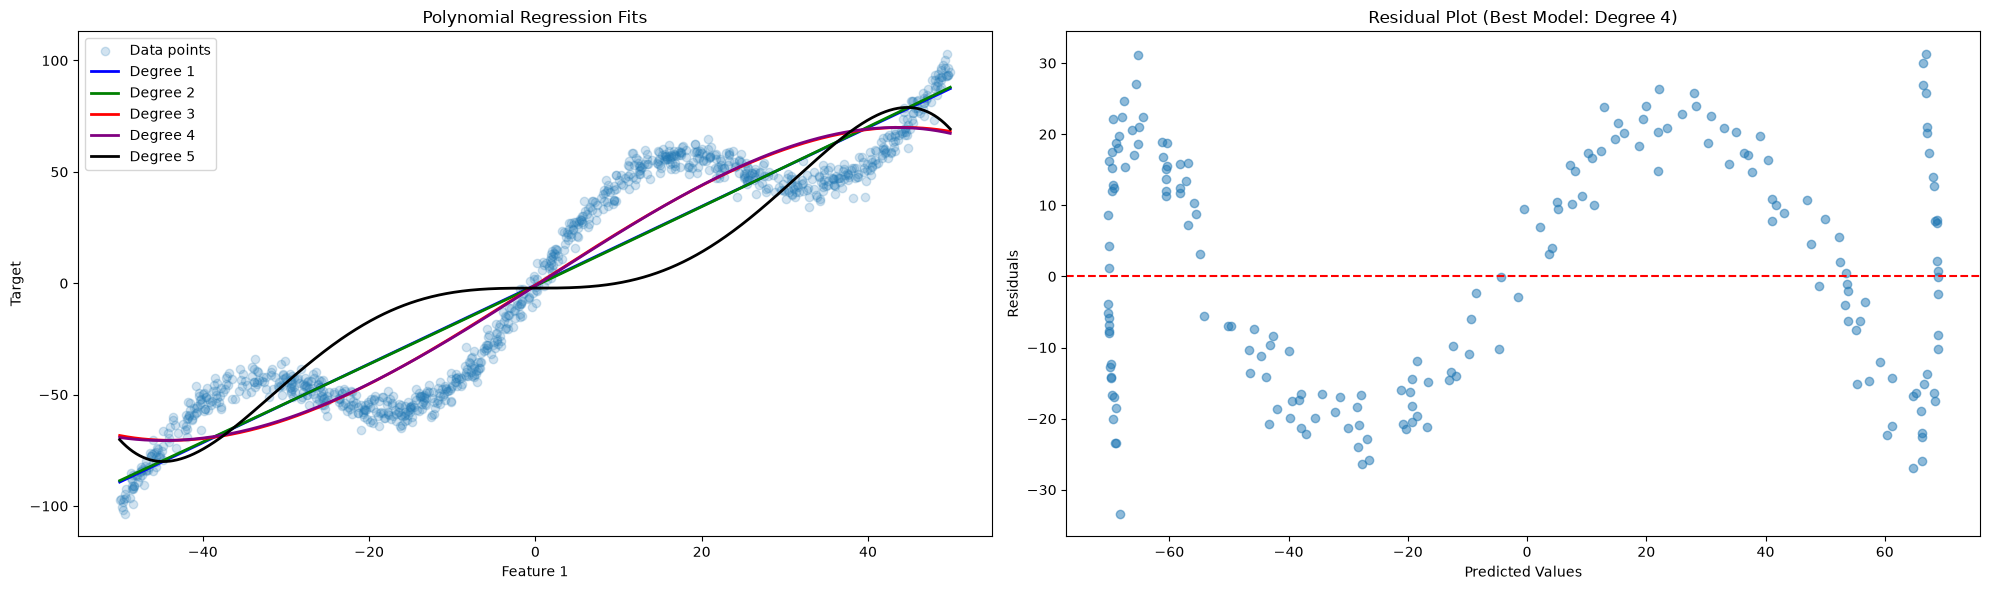

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

ax1.scatter(X['feature1'], y, alpha=0.2, label='Data points')

X_plot = np.linspace(
    X['feature1'].min(),
    X['feature1'].max(), 1000
).reshape(-1, 1)
colors = ['blue', 'green', 'red', 'purple', 'black']
for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    X_plot_poly = poly.fit_transform(X_plot)
    model = LinearRegression()
    model.fit(poly.fit_transform(X), y)
    y_plot = model.predict(X_plot_poly)
    ax1.plot(X_plot, y_plot, label=f'Degree {degree}',
             color=color, linewidth=2)
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Target')
ax1.set_title('Polynomial Regression Fits')
ax1.legend(loc='upper left')

best_degree = results_df.loc[
    results_df['R2'].idxmax(), 'Degree']
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_poly_best, y, test_size=0.2, random_state=123)
best_model = LinearRegression()
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred
ax2.scatter(y_pred, residuals, alpha=0.5)
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Values')
ax2.set_ylabel('Residuals')
ax2.set_title(
    f'Residual Plot (Best Model: Degree {best_degree})')
plt.tight_layout()
plt.show()

**Our result differs from the book's here.** The book's Figure 5.8 shows degree 5 as the best fit (its black curve follows the sine wave and its residual plot is titled "degree 5"). In this environment
degree 5 is the *worst* of the five (MSE ≈ 811, R² ≈ 0.72) and degree 4 is picked as "best". The cause is numerical, not statistical — check the conditioning of the design matrix:

In [27]:
for d in degrees:
    print(f"degree {d}: condition number of the polynomial design matrix = {np.linalg.cond(PolynomialFeatures(d).fit_transform(X)):.2e}")

# the SAME degree-5 least-squares model, but with standardised powers (well-conditioned)
Xtr5, Xte5, ytr5, yte5 = train_test_split(X.values, y.values, test_size=0.2, random_state=123)
fixed5 = make_pipeline(PolynomialFeatures(5, include_bias=False), StandardScaler(), LinearRegression()).fit(Xtr5, ytr5)
print(f"\ndegree 5, unscaled powers (book's way): test MSE = {results_df.loc[results_df.Degree == 5, 'MSE'].iloc[0]:.1f}")
print(f"degree 5, standardised powers          : test MSE = {mean_squared_error(yte5, fixed5.predict(Xte5)):.1f}")

# what the solver did: LinearRegression treats tiny singular values as zero (parameter `tol`, default 1e-6)
P5 = PolynomialFeatures(5).fit_transform(X)
P5_tr, P5_te, y5_tr, y5_te = train_test_split(P5, y.values, test_size=0.2, random_state=123)
print()
for tol in (1e-6, 1e-9):
    m5 = LinearRegression(tol=tol).fit(P5_tr, y5_tr)
    print(f"LinearRegression(tol={tol:g}): rank_ = {m5.rank_} of 5 independent columns | test MSE = {mean_squared_error(y5_te, m5.predict(P5_te)):.1f}")

degree 1: condition number of the polynomial design matrix = 2.85e+01
degree 2: condition number of the polynomial design matrix = 1.63e+03
degree 3: condition number of the polynomial design matrix = 6.95e+04
degree 4: condition number of the polynomial design matrix = 3.87e+06
degree 5: condition number of the polynomial design matrix = 1.76e+08

degree 5, unscaled powers (book's way): test MSE = 811.1
degree 5, standardised powers          : test MSE = 48.3

LinearRegression(tol=1e-06): rank_ = 4 of 5 independent columns | test MSE = 811.1
LinearRegression(tol=1e-09): rank_ = 5 of 5 independent columns | test MSE = 48.3


With $x\in[-50,50]$ the columns $x,x^2,\dots,x^5$ range from 1 to $3\times10^8$ (condition number $\approx 10^8$ and growing fast with the degree). Newer scikit-learn versions give `LinearRegression` a `tol` parameter (default `1e-6`):
singular values smaller than `tol` times the largest are treated as zero. For the degree-5 design matrix the smallest singular value is only $\approx7\times10^{-8}$ of the largest, so the solver reports `rank_ = 4` and **silently drops one direction**, which is
why the fit is poor. Allowing smaller singular values (`tol=1e-9`) — or, better, **standardising the powers** — restores the full least-squares solution (MSE ≈ 48). So the book's degree-5 figure depends on your scikit-learn version
(older releases had no such cut-off): a practical reason to always scale polynomial features. (And degree 5 is *not* "best" even when it is fitted well: the extension below shows degrees 7–15 are better.)

Two further observations the book does not make:

* **Degrees 1 & 2 coincide, and 3 & 4 coincide** (look at the left plot, and the table: identical MSE/R² in pairs). The target is an *odd* function of $x$ ($2x$ and $\sin(x/8)$ are both odd), so the even-power coefficients are ≈ 0 and adding $x^2$ or $x^4$ changes nothing.
* **The residual plot still shows structure** (bands and patterns along the predicted values): a low-degree polynomial cannot capture the later oscillations of the sine wave. A good model leaves structureless residuals.

> **Book correction (model selection).** The text says the best model "is not always the one with the highest R² but the one with the lowest MSE" and warns about overfitting, yet it then **selects the degree using the test set** (`idxmax` of the *test* R²).
> Choosing a hyper-parameter on the test set leaks test information and makes the reported score optimistic. The degree should be chosen by **cross-validation on the training set**, as done next.

**Extension — choose the degree properly, and see overfitting.** Pipelines with standardisation (powers of $x$ up to $50^{15}$ otherwise make the problem numerically ill-conditioned), 5-fold CV over degrees 1–15:

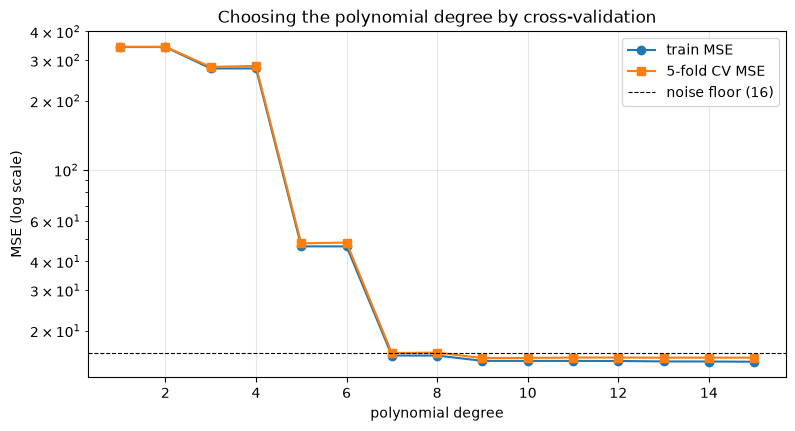

,CV MSE,train MSE,test MSE
degree,,,
1,343.0,342.1,317.0
3,280.4,276.1,268.5
5,47.9,46.5,48.3
7,16.0,15.6,15.9
9,15.2,14.8,14.9
11,15.3,14.8,14.9
13,15.3,14.7,15.2
15,15.3,14.6,15.3


best degree by CV: 9


In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold

Xa, ya = data[['feature1']].values, data['target'].values
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(Xa, ya, test_size=0.2, random_state=123)
kf = KFold(5, shuffle=True, random_state=123)

rows = []
for d in range(1, 16):
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    cv_mse = -cross_val_score(pipe, Xtr_a, ytr_a, cv=kf, scoring="neg_mean_squared_error").mean()
    pipe.fit(Xtr_a, ytr_a)
    rows.append({"degree": d, "CV MSE": cv_mse, "train MSE": mean_squared_error(ytr_a, pipe.predict(Xtr_a)), "test MSE": mean_squared_error(yte_a, pipe.predict(Xte_a))})
poly_cv = pd.DataFrame(rows).set_index("degree")

plt.figure(figsize=(9, 4.5))
plt.semilogy(poly_cv.index, poly_cv["train MSE"], "o-", label="train MSE"); plt.semilogy(poly_cv.index, poly_cv["CV MSE"], "s-", label="5-fold CV MSE")
plt.axhline(16, c="k", ls="--", lw=.8, label="noise floor (16)")
plt.xlabel("polynomial degree"); plt.ylabel("MSE (log scale)"); plt.title("Choosing the polynomial degree by cross-validation"); plt.legend(); plt.grid(alpha=.3); plt.show()
display(poly_cv.loc[[1, 3, 5, 7, 9, 11, 13, 15]].round(1))
print("best degree by CV:", int(poly_cv["CV MSE"].idxmin()))

Degrees 1–4 under-fit (CV MSE 280–340, far above the noise floor 16); **the book's degree 5 still under-fits** (CV MSE ≈ 48) because a sine wave over several periods needs more flexibility; **degree 7 reaches the noise floor** (≈ 16)
and the CV minimum is at degree 9 (15.2). Beyond that the curve is flat: with 800 training points and low noise there is **no visible overfitting up to degree 15**, so the train/CV gap stays tiny. (Overfitting needs fewer points or more noise — see the 60-sample
experiment in Section 4.) Polynomials are an inefficient basis for oscillating functions, and they behave badly outside the training range (see the extrapolation plot below), which is why the book moves on to splines.

**Extension — does a Ridge penalty help a polynomial?** Only when there is overfitting to cure:

In [29]:
rows = []
for d in (10, 15):
    for a in (1e-4, 1e-2, 1, 100):
        pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), Ridge(alpha=a))
        rows.append({"degree": d, "alpha": a, "CV MSE": -cross_val_score(pipe, Xtr_a, ytr_a, cv=kf, scoring="neg_mean_squared_error").mean()})
pd.DataFrame(rows).pivot(index="alpha", columns="degree", values="CV MSE").round(1)

degree,10,15
alpha,,
0.0001,15.2,15.2
0.0100,17.2,16.2
1.0000,67.4,52.6
100.0000,426.2,415.3


Here the unpenalised fit is already at the floor (15.2 at `alpha=1e-4`) and every substantial penalty makes it *worse* (alpha ≥ 1). Regularisation is a **remedy for overfitting, not a free improvement**: it helps when the model has more freedom than the data can support.

### Spline regression — how to do it…
`SplineTransformer` expands $x$ into a **B-spline basis**: piecewise cubic polynomials that join smoothly at *knots*. A linear model on this basis is a *regression spline*. The book fits 3, 5, 7 knots (degree 3).

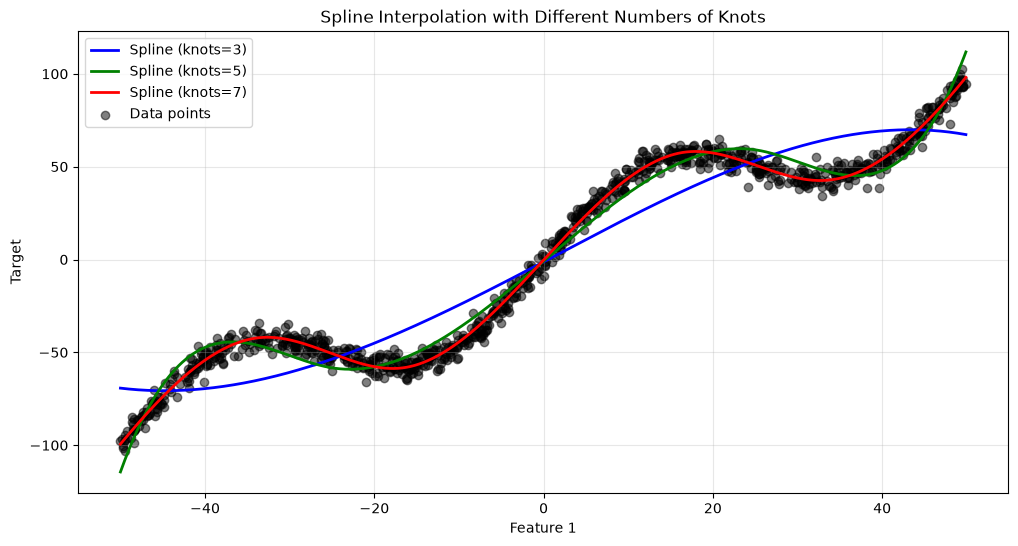

,Number of Knots,MSE,R-squared
0,3,274.267019,0.904652
1,5,55.347798,0.980759
2,7,15.502097,0.994611


In [30]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

X_plot_df = pd.DataFrame(X_plot, columns=['feature1'])      # (fix: the book predicts with a bare array after fitting on a DataFrame, which triggers a feature-name warning)

n_knots = [3, 5, 7]  # Different numbers of knots to try
plt.figure(figsize=(12, 6))

mse_scores = []
r2_scores = []
for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    y_pred = model.predict(X_plot_df)
    y_pred_train = model.predict(X)

    mse = mean_squared_error(y, y_pred_train)
    r2 = r2_score(y, y_pred_train)
    mse_scores.append(mse)
    r2_scores.append(r2)

    plt.plot(X_plot, y_pred,
             label=f'Spline (knots={n_knot})',
             color=color,
             linewidth=2)

plt.scatter(X, y, color='black', alpha=0.5,
            label='Data points')
plt.xlabel('Feature 1')
plt.ylabel('Target')
plt.title('Spline Interpolation with Different Numbers of Knots')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

metrics_df = pd.DataFrame({
    'Number of Knots': n_knots,
    'MSE': mse_scores,
    'R-squared': r2_scores
})
display(metrics_df)

The numbers match the book's Figure 5.10 (MSE ≈ 274 → 55 → 15.5, R² ≈ 0.905 → 0.981 → 0.995). Notice that 7 knots already reach MSE ≈ 15.5, i.e. **the noise floor of 16** — there is nothing left to learn.

> **Book corrections for splines.**
> 1. The book concludes "as the number of knots increases, MSE decreases, indicating a better model fit". These are **training** errors (the model is fitted *and* scored on all the data), and training error *always* falls as flexibility grows — it is not evidence of better generalisation.
>    More knots can keep lowering training error by fitting noise. Judge with cross-validation (next cell).
> 2. The text calls this "spline **interpolation**", a curve passing *through* the points. `SplineTransformer` + `LinearRegression` is a **regression spline** (least-squares fit of a smooth curve *near* the points). True interpolation (shown below) reproduces the noise.
> 3. In `SplineTransformer`, `n_knots` counts all knots *including the two boundary knots*.

**Extension — choose the number of knots (and degree) by cross-validation:**

n_knots,3,5,7,10,15,20,30,50
train MSE,276.04,55.05,15.38,14.7,14.58,14.54,14.38,13.80
CV MSE,283.10,56.37,15.74,15.2,15.24,15.41,15.81,15.97


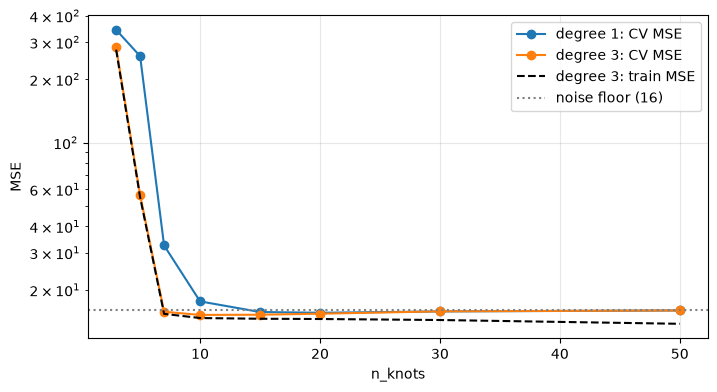

In [31]:
rows = []
for deg in (1, 3):
    for k in (3, 5, 7, 10, 15, 20, 30, 50):
        pipe = make_pipeline(SplineTransformer(n_knots=k, degree=deg), LinearRegression())
        cv_mse = -cross_val_score(pipe, Xtr_a, ytr_a, cv=kf, scoring="neg_mean_squared_error").mean()
        pipe.fit(Xtr_a, ytr_a)
        rows.append({"degree": deg, "n_knots": k, "train MSE": mean_squared_error(ytr_a, pipe.predict(Xtr_a)), "CV MSE": cv_mse})
spl = pd.DataFrame(rows)
display(spl[spl["degree"] == 3].set_index("n_knots")[["train MSE", "CV MSE"]].round(2).T)

fig, ax = plt.subplots(figsize=(8, 4.2))
for deg, g in spl.groupby("degree"):
    ax.plot(g["n_knots"], g["CV MSE"], "o-", label=f"degree {deg}: CV MSE")
ax.plot(spl[spl.degree == 3]["n_knots"], spl[spl.degree == 3]["train MSE"], "k--", label="degree 3: train MSE")
ax.axhline(16, c="grey", ls=":", label="noise floor (16)"); ax.set_yscale("log"); ax.set_xlabel("n_knots"); ax.set_ylabel("MSE"); ax.legend(); ax.grid(alpha=.3); plt.show()

The CV error of the cubic spline reaches the noise floor (≈ 16) at about 7–10 knots and then stays flat — and starts creeping *up* (15.2 at 10 knots → 16.0 at 50) while the training error keeps falling (14.7 → 13.8): the widening gap
between the two is the beginning of overfitting. **Extra knots add nothing** — a model with ~8–10 knots is as good as one with 50, and simpler. (With very many knots, a penalty such as Ridge on the basis coefficients keeps the curve smooth.)

**Extension — interpolation vs regression, and extrapolation.** A cubic *interpolating* spline passes through every noisy training point; compare it with the regression spline, and see how each model behaves beyond the training range $[-50, 50]$.

interpolating spline : train MSE      0.00 | test MSE   1042.17  (memorises the noise)
regression spline    : train MSE     15.20 | test MSE     14.68  (noise floor = 16)


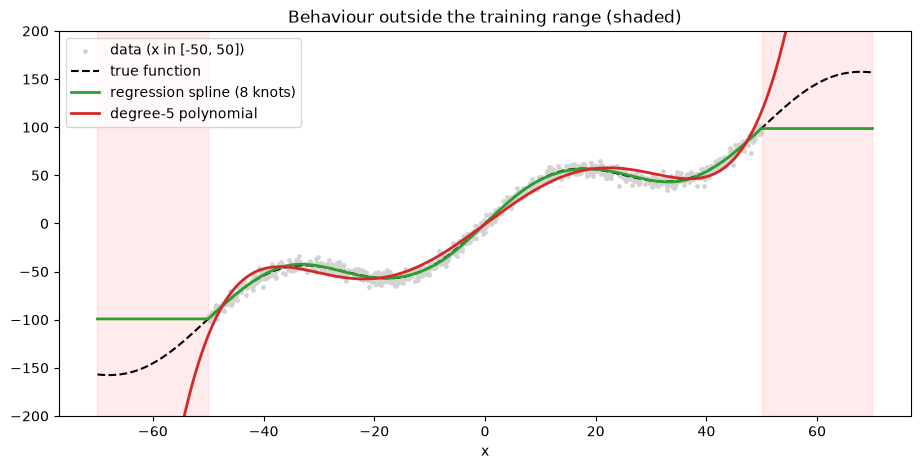

In [32]:
from scipy.interpolate import CubicSpline

order = np.argsort(Xtr_a[:, 0]); xs, ys_ = Xtr_a[order, 0], ytr_a[order]
interp = CubicSpline(xs, ys_)
reg_spline = make_pipeline(SplineTransformer(n_knots=8, degree=3), LinearRegression()).fit(Xtr_a, ytr_a)
poly5 = make_pipeline(PolynomialFeatures(5, include_bias=False), StandardScaler(), LinearRegression()).fit(Xtr_a, ytr_a)

print(f"interpolating spline : train MSE {mean_squared_error(ytr_a, interp(Xtr_a[:, 0])):9.2f} | test MSE {mean_squared_error(yte_a, interp(Xte_a[:, 0])):9.2f}  (memorises the noise)")
print(f"regression spline    : train MSE {mean_squared_error(ytr_a, reg_spline.predict(Xtr_a)):9.2f} | test MSE {mean_squared_error(yte_a, reg_spline.predict(Xte_a)):9.2f}  (noise floor = 16)")

xx = np.linspace(-70, 70, 600).reshape(-1, 1)
true_f = 2 * xx[:, 0] + 27 * np.sin(xx[:, 0] / 8)
plt.figure(figsize=(11, 5))
plt.scatter(Xa, ya, s=6, c="lightgrey", label="data (x in [-50, 50])")
plt.plot(xx, true_f, "k--", label="true function")
plt.plot(xx, reg_spline.predict(xx), c="tab:green", lw=2, label="regression spline (8 knots)")
plt.plot(xx, poly5.predict(xx), c="tab:red", lw=2, label="degree-5 polynomial")
plt.axvspan(-70, -50, alpha=.08, color="r"); plt.axvspan(50, 70, alpha=.08, color="r")
plt.ylim(-200, 200); plt.xlabel("x"); plt.legend(loc="upper left"); plt.title("Behaviour outside the training range (shaded)"); plt.show()

The interpolating spline has zero training error but a test error far above the noise floor (it chases noise), while the regression spline sits at the floor. Outside the data range the polynomial diverges rapidly
(high-degree polynomials are dangerous for extrapolation) whereas `SplineTransformer` extrapolates as a constant by default (`extrapolation="constant"`) — safe but flat; neither knows the true function out there.

### How it works…
* **Polynomial regression:** $y=\beta_0+\beta_1x+\beta_2x^2+\dots+\beta_dx^d+\epsilon$ — still *linear in the coefficients*, so least squares applies; the feature matrix is the Vandermonde matrix, whose columns become highly correlated (multicollinearity again) as $d$ grows.
* **Splines:** a cubic B-spline basis is a set of local bumps, each non-zero only over a few knot intervals; the fit is the least-squares combination of these bumps, continuous with continuous first and second derivatives at the knots.
  Flexibility is controlled by the number of knots (more knots = more wiggle), the degree, and optionally a penalty on the coefficients.
* **Why splines beat polynomials for local structure:** a polynomial's coefficient affects the curve everywhere (global); a spline's affects only a neighbourhood (local), so a wiggle in one region does not distort the rest.

### Theory
* **Capacity and regularisation again:** degree (polynomial) and number of knots (spline) are complexity knobs; choose them by cross-validation, and add Ridge/Lasso to tame them — Section 4's bias–variance logic applies unchanged.
* **Beyond the book:** natural splines (linear beyond the boundary knots), smoothing splines (penalised), GAMs (generalised additive models: one spline per feature), `KBinsDiscretizer` (piecewise-constant) and kernel/tree methods for non-linearity.
* **Noise floor:** the best achievable test MSE equals the noise variance; training MSE below it signals overfitting.

### Hands-on workflow (from the book)
Dataset → pre-process → `PolynomialFeatures` + linear model → MSE/R² → `SplineTransformer` + linear model → MSE/R² → compare (done above, with CV-based selection).

## 6. Practical exercises with regularization techniques

The book asks you to build, tune and evaluate Ridge, Lasso and ElasticNet on synthetic data ("use `random_state=123` / `np.random.seed(123)`"). The steps are the same for the three exercises:
**load libraries → generate synthetic data with noise → split → fit → predict → metrics → print → visualise (sorted X for a smooth line).**

### Exercise 1 — Ridge regression
A single-feature dataset so the fitted line can be drawn.

Ridge(alpha=10)  MSE = 199.03   R2 = 0.743   slope = 20.65   intercept = -2.29


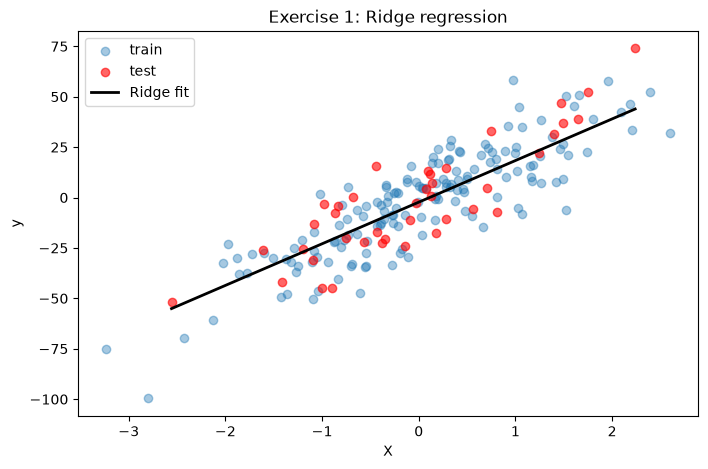

In [33]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(123)
X1, y1 = make_regression(n_samples=200, n_features=1, noise=15, random_state=123)
X1_tr, X1_te, y1_tr, y1_te = train_test_split(X1, y1, test_size=0.2, random_state=123)

ridge1 = Ridge(alpha=10.0).fit(X1_tr, y1_tr)
pred = ridge1.predict(X1_te)
print(f"Ridge(alpha=10)  MSE = {mean_squared_error(y1_te, pred):.2f}   R2 = {r2_score(y1_te, pred):.3f}   slope = {ridge1.coef_[0]:.2f}   intercept = {ridge1.intercept_:.2f}")

order = np.argsort(X1_te[:, 0])                         # sort X for a smooth line
plt.figure(figsize=(8, 5))
plt.scatter(X1_tr, y1_tr, alpha=.4, label="train"); plt.scatter(X1_te, y1_te, c="r", alpha=.6, label="test")
plt.plot(X1_te[order], pred[order], "k-", lw=2, label="Ridge fit")
plt.xlabel("X"); plt.ylabel("y"); plt.title("Exercise 1: Ridge regression"); plt.legend(); plt.show()

### Exercise 2 — Lasso regression (and comparison with Ridge)

Lasso(alpha=1)   MSE = 197.52   R2 = 0.745   slope = 20.91   intercept = -2.29
OLS              MSE = 193.42


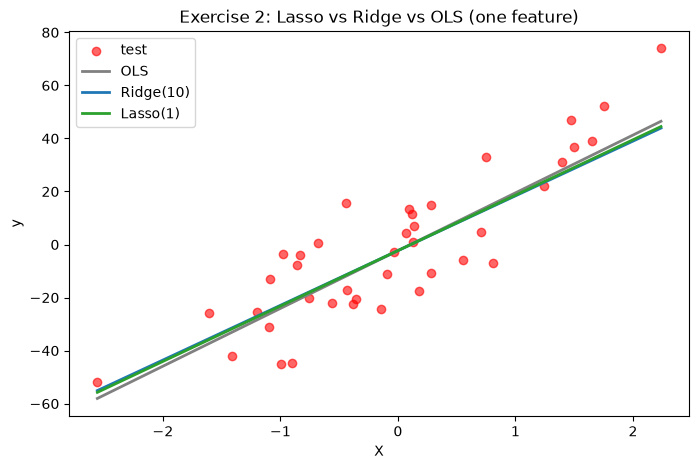

In [34]:
lasso1 = Lasso(alpha=1.0).fit(X1_tr, y1_tr)
pred_l = lasso1.predict(X1_te)
print(f"Lasso(alpha=1)   MSE = {mean_squared_error(y1_te, pred_l):.2f}   R2 = {r2_score(y1_te, pred_l):.3f}   slope = {lasso1.coef_[0]:.2f}   intercept = {lasso1.intercept_:.2f}")
print(f"OLS              MSE = {mean_squared_error(y1_te, LinearRegression().fit(X1_tr, y1_tr).predict(X1_te)):.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(X1_te, y1_te, c="r", alpha=.6, label="test")
for name, m, c in [("OLS", LinearRegression().fit(X1_tr, y1_tr), "grey"), ("Ridge(10)", ridge1, "tab:blue"), ("Lasso(1)", lasso1, "tab:green")]:
    plt.plot(X1_te[order], m.predict(X1_te)[order], c=c, lw=2, label=name)
plt.legend(); plt.xlabel("X"); plt.ylabel("y"); plt.title("Exercise 2: Lasso vs Ridge vs OLS (one feature)"); plt.show()

With a **single** feature and plenty of data, the three lines are almost identical — the penalty only shrinks the slope slightly and there is nothing to select or stabilise. This is why regularisation is demonstrated on many-feature data.
The effect of `alpha` on the slope (a feature-less problem has nothing else to show):

In [35]:
rows = []
for a in (0, 1, 10, 100, 1000, 10000):
    r = Ridge(alpha=a).fit(X1_tr, y1_tr) if a else LinearRegression().fit(X1_tr, y1_tr)
    l = Lasso(alpha=a).fit(X1_tr, y1_tr) if a else LinearRegression().fit(X1_tr, y1_tr)
    rows.append({"alpha": a, "Ridge slope": r.coef_[0], "Lasso slope": l.coef_[0]})
pd.DataFrame(rows).set_index("alpha").round(2)

,Ridge slope,Lasso slope
alpha,,
0,21.80,21.80
1,21.68,20.91
10,20.65,12.87
100,13.99,0.00
1000,3.31,0.00
10000,0.38,0.00


Both slopes shrink towards 0 as `alpha` grows; Lasso reaches **exactly 0** at `alpha` large enough (soft-thresholding), Ridge only approaches it.

### Exercise 3 — ElasticNet regression

In [36]:
en1 = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123).fit(X1_tr, y1_tr)
pred_e = en1.predict(X1_te)
print(f"ElasticNet(alpha=1, l1_ratio=0.5) MSE = {mean_squared_error(y1_te, pred_e):.2f}   R2 = {r2_score(y1_te, pred_e):.3f}   slope = {en1.coef_[0]:.2f}")
print(f"OLS slope for reference = {LinearRegression().fit(X1_tr, y1_tr).coef_[0]:.2f}")

ElasticNet(alpha=1, l1_ratio=0.5) MSE = 271.37   R2 = 0.650   slope = 14.76
OLS slope for reference = 21.80


This `alpha=1` ElasticNet shrinks the slope noticeably (about 15 vs 22 for OLS) and is the *worst* of the four lines here: with one feature and 160 training points there is no overfitting to remove, so any penalty only adds bias.
Again `alpha` must be tuned (or kept tiny) rather than picked by habit — the multi-feature comparison below is where the penalties earn their keep.

### The comparison the book asks for — on data where regularisation matters
"Compare the performance of the two" / "How well does ElasticNet perform compared to the other two?" is only meaningful when there are many features, some irrelevant and some correlated. I build such a dataset
(40 features, 6 informative, plus 10 noisy copies of informative features; **only 60 training samples**, 300 test samples), select each model's hyper-parameters by cross-validation, and compare on a held-out test set — including **how close each model's coefficients are to the truth**.
(With 150 training samples all four methods were nearly tied, so the small training set is deliberate: regularisation matters when $n$ is not much larger than $p$.)

In [37]:
def make_exercise_data(n_train, seed=123, n_test=300):
    Xe, ye, coef_e = make_regression(n_samples=n_train + n_test, n_features=40, n_informative=6, noise=25, random_state=seed, coef=True)
    rng = np.random.default_rng(seed)
    inf_e = np.flatnonzero(coef_e); non_e = np.flatnonzero(coef_e == 0)
    Xe[:, non_e[:10]] = Xe[:, np.resize(inf_e, 10)] + rng.normal(0, 0.1, size=(n_train + n_test, 10))   # 10 correlated copies of informative features
    return Xe[:n_train], ye[:n_train], Xe[n_train:], ye[n_train:], coef_e, inf_e

Xe_tr, ye_tr, Xe_te, ye_te, coef_e, inf_e = make_exercise_data(60)                              # small training set, large test set

models = {
    "OLS": LinearRegression(),
    "RidgeCV": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 40))),
    "LassoCV": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=123, max_iter=20000)),
    "ElasticNetCV": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .3, .5, .7, .9, .95], cv=5, random_state=123, max_iter=20000)),
}
rows = []
for name, m in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); m.fit(Xe_tr, ye_tr)
    est = m[-1] if hasattr(m, "steps") else m
    coef = np.asarray(est.coef_)
    if hasattr(m, "steps"): coef = coef / m[0].scale_                        # back to original units to compare with the true coefficients
    p = m.predict(Xe_te)
    selected = set(np.flatnonzero(np.abs(coef) > 1e-6)) if name in ("LassoCV", "ElasticNetCV") else set(range(40))
    rows.append({"model": name, "test R2": r2_score(ye_te, p), "test RMSE": np.sqrt(mean_squared_error(ye_te, p)),
                 "non-zero coefs": len(selected), "true features found (of 6)": len(selected & set(inf_e)),
                 "coef error (L2 vs truth)": np.linalg.norm(coef - coef_e),
                 "alpha": getattr(est, "alpha_", np.nan), "l1_ratio": getattr(est, "l1_ratio_", np.nan)})
res_e = pd.DataFrame(rows).set_index("model")
res_e.round(3)

,test R2,test RMSE,non-zero coefs,true features found (of 6),coef error (L2 vs truth),alpha,l1_ratio
model,,,,,,,
OLS,0.663,48.938,40,6,384.085,NaN,NaN
RidgeCV,0.857,31.878,40,6,61.231,10.000,NaN
LassoCV,0.889,28.068,23,4,60.042,1.472,NaN
ElasticNetCV,0.881,29.066,32,6,56.861,1.445,0.95


How to read this table (one seeded dataset; the repeated-datasets table below checks that the pattern is not a fluke):
* With only 60 samples for 40 features, **OLS overfits** (much lower test R²) and its coefficients are far from the truth (`coef error` several times larger). All three regularised models fix most of that.
* **Lasso** gives a *sparse* model (23 of 40 coefficients non-zero, instead of all 40) and the lowest test RMSE, but it recovers only **4 of the 6 true feature columns**: for two of them it kept a correlated *copy* instead of the original (Lasso's arbitrary choice among correlated features).
* **ElasticNet** keeps a larger group (32 non-zero; the correlated copies share the weight), finds all 6 true features and has the smallest coefficient error here; **Ridge** keeps all 40 features with shrunken, evenly shared weights.
* The ranking among the three regularised models is close and depends on the dataset — which is exactly why `alpha`/`l1_ratio` are chosen by cross-validation instead of fixed in advance.

**Is it a fluke of one seed?** Repeat with 10 different datasets (and a larger training set for contrast):

In [38]:
def one_run(n_train, seed):
    Xtr, ytr, Xte, yte, coef_true, _ = make_exercise_data(n_train, seed)
    ms = {"OLS": LinearRegression(),
          "RidgeCV": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 40))),
          "LassoCV": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=20000)),
          "ElasticNetCV": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .3, .5, .7, .9, .95], cv=5, random_state=0, max_iter=20000))}
    out = {}
    for n, m in ms.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore"); m.fit(Xtr, ytr)
        est = m[-1] if hasattr(m, "steps") else m
        coef = np.asarray(est.coef_) / (m[0].scale_ if hasattr(m, "steps") else 1)
        out[n] = (r2_score(yte, m.predict(Xte)), np.linalg.norm(coef - coef_true), int((np.abs(coef) > 1e-6).sum()))
    return out

summary = {}
for n_train in (60, 150):
    runs = [one_run(n_train, s) for s in range(10)]
    for model in runs[0]:
        arr = np.array([r[model] for r in runs])
        summary[(f"n_train={n_train}", model)] = {"mean test R2": arr[:, 0].mean(), "mean coef error": arr[:, 1].mean(), "mean non-zero coefs": arr[:, 2].mean()}
pd.DataFrame(summary).T.round(3)

mean test R2  mean coef error  mean non-zero coefs
n_train=60  OLS                  0.885          257.002                 40.0
            RidgeCV              0.920          110.557                 40.0
            LassoCV              0.946           85.256                 18.3
            ElasticNetCV         0.936           99.493                 30.2
n_train=150 OLS                  0.955          104.859                 40.0
            RidgeCV              0.957           91.909                 40.0
            LassoCV              0.962           56.734                 17.3
            ElasticNetCV         0.960           96.439                 29.7

Averaged over 10 datasets, with 60 training samples OLS is clearly worst on both test R² and coefficient error, Lasso/ElasticNet are best and Lasso is the sparsest; with 150 samples the gap in R² nearly closes (OLS has enough data)
but the regularised models still recover the coefficients better and Lasso still gives the most compact model. **Regularisation matters most when $n$ is small relative to $p$.**

A picture of the coefficients (true vs estimated; red bars are the 6 informative features):

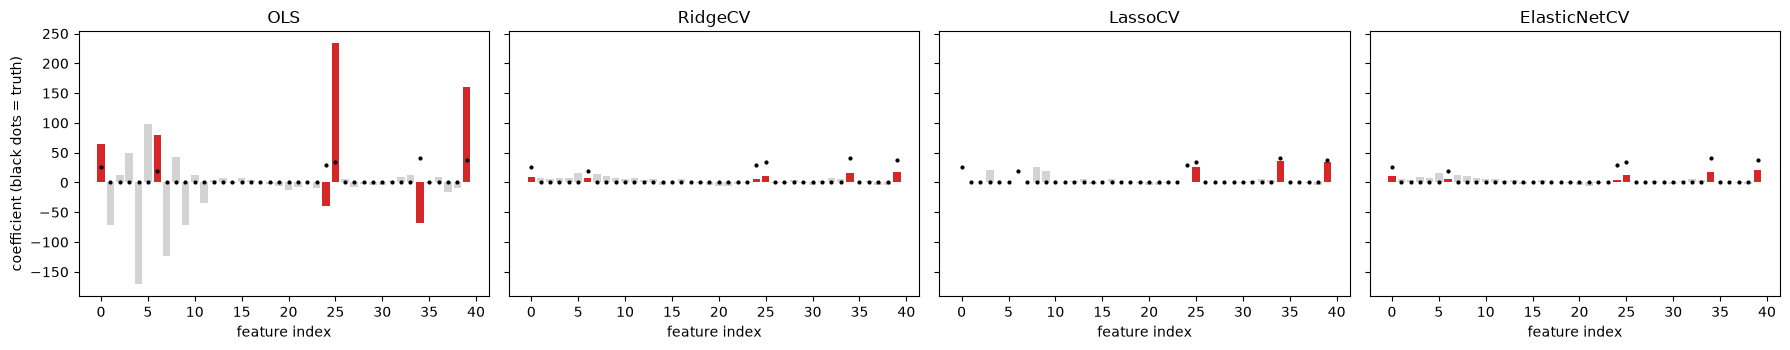

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    est = m[-1] if hasattr(m, "steps") else m
    coef = np.asarray(est.coef_) / (m[0].scale_ if hasattr(m, "steps") else 1)
    ax.bar(range(40), coef, color=["tab:red" if i in set(inf_e) else "lightgrey" for i in range(40)])
    ax.plot(range(40), coef_e, "k.", ms=4); ax.set_title(name); ax.set_xlabel("feature index")
axes[0].set_ylabel("coefficient (black dots = truth)")
plt.tight_layout(); plt.show()

### Theory (for the exercises)
* **Why use a single feature to draw but many to compare?** A 2-D plot can only show one feature; but regularisation's value (stabilisation, selection, variance reduction) needs $p$ large relative to $n$ and some collinearity.
* **Use `*CV` estimators (or a `GridSearchCV` over `alpha`, `l1_ratio`)** with a scaler in the pipeline; report test metrics once.
* **Evaluate selection** with something beyond R²: the number of non-zero coefficients, stability across resamples, and (on synthetic data) recovery of the true support.

## Chapter takeaways
1. **OLS** minimises squared error and has a closed form; it predicts well on clean, low-dimensional data but has unstable coefficients under multicollinearity and overfits when $p$ is large relative to $n$.
2. **Ridge (L2)** shrinks all coefficients smoothly and stabilises collinear predictors; **Lasso (L1)** shrinks *and* zeroes coefficients (feature selection); **ElasticNet** combines both and handles correlated groups.
3. **`alpha` is relative to the scale of the data.** Standardise features (and consider the target) and choose `alpha` / `l1_ratio` by cross-validation (`RidgeCV`, `LassoCV`, `ElasticNetCV`) — never by eye or by the test set.
4. **Regularisation trades a little bias for a lot less variance**; the best `alpha` minimises error on unseen data, with over- and under-fitting on either side.
5. **Polynomial and spline regression** make linear models non-linear; choose degree / number of knots by cross-validation, compare against the noise floor, and prefer splines for local, oscillating structure and for stability outside the data range.
6. **Check the data and the claims:** a flawed synthetic dataset (overwritten signal) can make every model look the same and make an untuned model look "best".

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| First dataset | multicollinearity explains the poor R² (≈ 0.1) | the loop overwrites 7 of the 10 informative columns after `y` was generated, destroying the signal; OLS gets R² 0.99 on the un-overwritten data |
| Reproducibility | correlated features built with unseeded `np.random.normal` | results change each run; seed added |
| Ridge/Lasso/ElasticNet `alpha` | values 1 and 10 used as meaningful penalties | with a target of scale ~10⁴ these penalties are negligible; `alpha` must be tuned by CV relative to data scale |
| Coefficient-path plot | "some coefficients go to exactly 0 … paths show which features matter" | in the book's own setting **no** coefficient is ever 0 (even at `alpha=100`); the described behaviour only appears on a standardised target |
| "ElasticNet performs best" | based on one split with untuned `alpha=1` | within noise on the book's data; **worse than OLS** on the rebuilt strong-signal data |
| Loss formulas | Lasso/ElasticNet written without scikit-learn's $\frac1{2n}$ factor and with weights $\lambda_1,\lambda_2$ | scikit-learn uses $\frac1{2n}\mathrm{RSS}+\alpha(\rho\lVert\beta\rVert_1+\frac{1-\rho}2\lVert\beta\rVert_2^2)$ |
| Polynomial degree | picks the "best" degree on the test set (and says the best is not the highest R²); reports degree 5 as best | select by cross-validation; with unscaled powers current `LinearRegression` (`tol=1e-6`) drops a direction (`rank_=4`, test MSE ≈ 811) — scale the powers; even then degree 5 under-fits (CV MSE ≈ 48 vs noise floor 16) and degrees 7–9 are best |
| Line-plot code | predicts with a DataFrame after fitting on a NumPy array | triggers a "feature names" warning; arrays used here |
| Spline | "as knots increase MSE decreases → better fit"; called "interpolation" | those are training errors; `SplineTransformer` + `LinearRegression` is a regression spline (interpolation would pass through the noisy points); CV flattens at ≈ 7–10 knots |
| Spline code | predicts with a bare NumPy array after fitting on a DataFrame | triggers a feature-name warning; DataFrame used instead |

*All five chapters are now complete.*